In [1]:
#--------------Set working directory----------------------------------------#
import os
os.chdir("C:/Users/PC/Desktop/Togo_AI_Lab_Technical_Assessment")

In [ ]:
#----------------------Missing libraries installation----------------------#
#We need package @plotly to plot maps, geopandas to read geo-spatial data. 
#Pandas can be installed if not yet installed
#geopandas depends on pyogrio which must be installed
#h2o is machine learning library we choose

missing_packages=["plotly","pandas","geopandas","pyogrio","xarray","netCDF4","h5netcdf","kaleido"]
!pip install plotly pandas geopandas pyogrio
!pip install --upgrade plotly
!pip install xarray
!pip install h5netcdf
!pip install netCDF4
!pip install --upgrade "kaleido>=1"

In [4]:
#-------------------------Used Libraries importation-------------
import pandas as pd
from pandas.api.types import is_numeric_dtype, is_categorical_dtype
import geopandas as gpd
import pyogrio
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "iframe"
import plotly.graph_objects as go
import json
import scipy as sp
import sys
import random
import datetime
from datetime import date
import numpy as np
import kaleido #for image exporting as image
import xarray as xr # for omportation of NetCDF file
import netCDF4

import warnings
warnings.filterwarnings("ignore")

output_dir = "figures"
os.makedirs(output_dir, exist_ok=True)

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# call of ML modules
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,RidgeCV,ridge_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score

from math import log as mathlog
import statistics

# TASK1: Data Cleaning, Geospatial Wrangling, and Exploration

### 1. Administrative boundary joint data for Togo and Benin

In [6]:
#-----------------------Geo spatial data importation for Togo

togo_geo_data = gpd.read_file("data/administrative_boundaries/gadm41_TGO_2.geojson", engine="pyogrio")
togo_geo_data=togo_geo_data.rename(columns={'COUNTRY':'Country','NAME_1':'Region','NAME_2':'Commune'})

In [7]:
#-----------------------Geo spatial data importation for Benin

benin_geo_data = gpd.read_file("data/administrative_boundaries/gadm41_BEN_2.geojson", engine="pyogrio")
benin_geo_data=benin_geo_data.rename(columns={'COUNTRY':'Country','NAME_1':'Region','NAME_2':'Commune'})

In [8]:
#----------Merging @togo_geo_data and @ benin_geo_data
togo_benin_geo_data=togo_geo_data._append(benin_geo_data)

In [9]:
#--------Get centroind, area and boundaries of polygones
togo_benin_geo_data["area"]=togo_benin_geo_data.area
togo_benin_geo_data["boundary"]=togo_benin_geo_data.boundary
togo_benin_geo_data["centroid"]=togo_benin_geo_data.centroid

In [10]:
print(togo_benin_geo_data.head())

       GID_2 GID_0 Country    GID_1  Region NL_NAME_1    Commune  \
0  TGO.1.1_2   TGO    Togo  TGO.1_1  Centre        NA     Blitta   
1  TGO.1.2_2   TGO    Togo  TGO.1_1  Centre        NA         Mô   
2  TGO.1.3_2   TGO    Togo  TGO.1_1  Centre        NA  Sotouboua   
3  TGO.1.4_2   TGO    Togo  TGO.1_1  Centre        NA    Tchamba   
4  TGO.1.5_2   TGO    Togo  TGO.1_1  Centre        NA   Tchaudjo   

          VARNAME_2 NL_NAME_2           TYPE_2       ENGTYPE_2 CC_2    HASC_2  \
0                NA        NA       Préfecture      Prefecture   NA  TG.CE.BL   
1                NA        NA  Sous-Préfecture  Sub-Prefecture   NA        NA   
2                NA        NA       Préfecture      Prefecture   NA  TG.CE.SO   
3     Nyala|Tchamba        NA       Préfecture      Prefecture   NA  TG.CE.TB   
4  Sokodé|Tchaoudjo        NA       Préfecture      Prefecture   NA  TG.CE.TD   

                                            geometry      area  \
0  MULTIPOLYGON (((0.6222 7.9015, 0.62

In [11]:
#-----------Merge or Dissolve polygons by region and by country
togo_benin_regions_data = togo_benin_geo_data.dissolve(by="Region").reset_index()
togo_benin_regions_data["Region_id"] = togo_benin_regions_data.index.astype(str)

togo_benin_countries_data = togo_benin_geo_data.dissolve(by="Country").reset_index()
togo_benin_countries_data["Country_id"] = togo_benin_countries_data.index.astype(str)

In [12]:
#----------Plotting of the map
country_geojson = json.loads(togo_benin_countries_data[["Country_id","Country", "geometry"]].to_json())
regions_geojson = json.loads(togo_benin_regions_data[["Region","Region_id","Country", "geometry"]].to_json())
commune_geojson = json.loads(togo_benin_geo_data[["Commune", "geometry"]].to_json())

In [14]:
#Plot on the same map regions and communes as demanded by the projetc task: we prefer identifying each county by a background color setting

fig = go.Figure()
# fig =fig.add_choroplethmap(
#     geojson=commune_geojson,
#     locations=togo_benin_geo_data["Commune"],
#     featureidkey="properties.Commune",
#     z=[1] * len(togo_benin_geo_data),
#     colorscale=[[0, "#DCEAF7"], [1, "#DCEAF7"]],
#     marker_line_width=0.9,
#     marker_line_color="violet",
#     showscale=False,
#     customdata=togo_benin_geo_data[["Country","Region", "Commune"]].to_numpy(),
#     hovertemplate="Country : %{customdata[0]}<br>Region : %{customdata[1]}<br>Commune : %{customdata[2]}<extra></extra>"
# )

bg_colors_list=[ "aqua","antiquewhite","aliceblue", "aquamarine"]
countries_list=togo_benin_geo_data.Country.unique().tolist()
for ctry in countries_list:
  print(ctry)
  subset_togo_benin_geo_data=togo_benin_geo_data[togo_benin_geo_data["Country"]==ctry]
  subset_commune_geojson = json.loads(subset_togo_benin_geo_data[["Commune", "geometry"]].to_json())
  fig =fig.add_choroplethmap(
      geojson=subset_commune_geojson,
      locations=subset_togo_benin_geo_data["Commune"],
      featureidkey="properties.Commune",
      z=[1] * len(subset_togo_benin_geo_data),
      colorscale=[[0, bg_colors_list[countries_list.index(ctry)]], [1, bg_colors_list[countries_list.index(ctry)]]],
      marker_line_width=0.9,
      marker_line_color="violet",
      showscale=False,
      customdata=subset_togo_benin_geo_data[["Country","Region", "Commune"]].to_numpy(),
      hovertemplate="Country : %{customdata[0]}<br>Region : %{customdata[1]}<br>Commune : %{customdata[2]}<extra></extra>"
  )

fig =fig.add_choroplethmap(
    geojson=regions_geojson,
    locations=togo_benin_regions_data["Region"],
    featureidkey="properties.Region",
    z=[1] * len(togo_benin_regions_data),
    colorscale=[[0, "rgba(255,255,255,0)"], [1, "rgba(255,255,255,0)"]],
    marker_line_width=2,
    marker_line_color="black",
    marker_opacity=1,
    showscale=False,
    hoverinfo="skip"
)

fig =fig.add_choroplethmap(
    geojson=country_geojson,
    locations=togo_benin_regions_data["Country"],
    featureidkey="properties.Country",
    z=[1] * len(togo_benin_regions_data),
    colorscale=[[0, "rgba(255,255,255,0)"], [1, "rgba(255,255,255,0)"]],
    marker_line_width=3,
    marker_line_color="red",
    marker_opacity=1,
    showscale=False,
    hoverinfo="skip"
)

fig=fig.update_layout(
    map=dict(
        style="carto-positron",
        center={"lat": 8.3, "lon": 1.1}, #centered around Togo and Bening
        zoom=5
        
    ),
    margin=dict(l=0, r=0, t=0, b=0)
)
fig.show()

Togo
Benin


In [15]:
#--------------------------Save the graph in directory @figures

fig.write_image(
    os.path.join(output_dir, "1.1.png"),
    width=1000,
    height=1000,
    scale=2
)

 ### 2. Maize yield data importation

In [16]:
#------------------------------Maize yield data importation

maize_data = pd.read_csv("data/administrative_yield/fews_net_yield_TGO_BEN.csv")
print( maize_data.head().to_string(index=False))

country admin_1   admin_2  year season_name season_type    value  unit      product
  Benin Alibori Banikoara  1999        Main     Harvest 1.207422 MT/ha Maize (Corn)
  Benin Alibori Banikoara  2000        Main     Harvest 1.103059 MT/ha Maize (Corn)
  Benin Alibori Banikoara  2001        Main     Harvest 1.178110 MT/ha Maize (Corn)
  Benin Alibori Banikoara  2002        Main     Harvest 1.194343 MT/ha Maize (Corn)
  Benin Alibori Banikoara  2003        Main     Harvest 1.468042 MT/ha Maize (Corn)


In [17]:
maize_data=maize_data.rename(columns={"admin_1":"Region","admin_2":"Commune","value":"maize_yield"})

In [18]:
print( maize_data.head().to_string(index=False))

country  Region   Commune  year season_name season_type  maize_yield  unit      product
  Benin Alibori Banikoara  1999        Main     Harvest     1.207422 MT/ha Maize (Corn)
  Benin Alibori Banikoara  2000        Main     Harvest     1.103059 MT/ha Maize (Corn)
  Benin Alibori Banikoara  2001        Main     Harvest     1.178110 MT/ha Maize (Corn)
  Benin Alibori Banikoara  2002        Main     Harvest     1.194343 MT/ha Maize (Corn)
  Benin Alibori Banikoara  2003        Main     Harvest     1.468042 MT/ha Maize (Corn)


In [19]:
def is_categorical_or_object(series):
 return is_categorical_dtype(series) or series.dtype == object

def plot_target_vs_features(df, target):
  features = [col for col in df.columns if col != target]
  n = len(features)
  # Loop through in steps of 2 to plot two per row
  for i in range(0, n, 2):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for j in range(2):
      if i + j >= n:
        break # avoid overflow
      col = features[i + j]
    
      ax = axes[j]
    
      if is_numeric_dtype(df[col]) and is_categorical_or_object(df[target]):
        sns.boxplot(x=target, y=col, data=df, ax=ax)
        ax.set_title(f'{col} vs {target} (Boxplot)')
    
      elif is_categorical_or_object(df[col]) and is_categorical_or_object(df[target]):
        sns.countplot(x=col, hue=target, data=df, ax=ax)
        ax.set_title(f'{col} vs {target} (Countplot)')
    
      elif is_numeric_dtype(df[col]) and is_numeric_dtype(df[target]):
        sns.scatterplot(x=col, y=target, data=df, ax=ax)
        ax.set_title(f'{col} vs {target} (Scatterplot)')
    
      elif is_categorical_or_object(df[col]) and is_numeric_dtype(df[target]):
        sns.boxplot(x=col, y=target, data=df, ax=ax)
        ax.set_title(f'{col} vs {target} (Boxplot)')
    
      else:
        ax.set_visible(False)
        print(f'Skipping column {col}: unsupported type')
  plt.xticks(rotation=90) # Rotate x-axis tick labels vertically
  plt.tight_layout()
  plt.show()


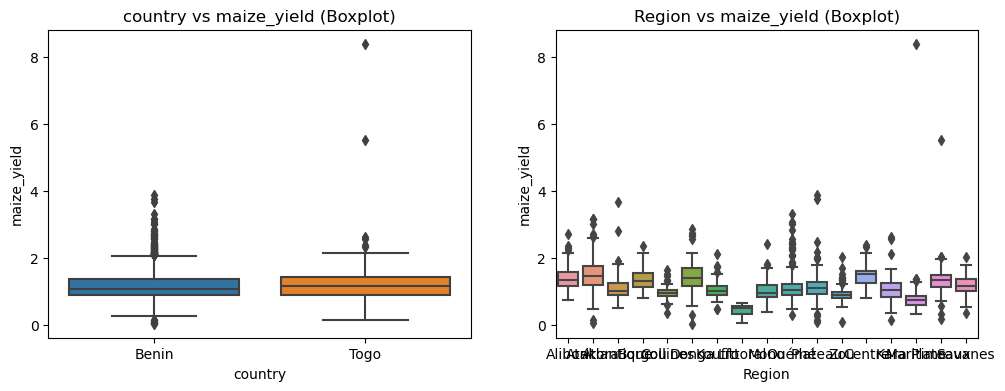

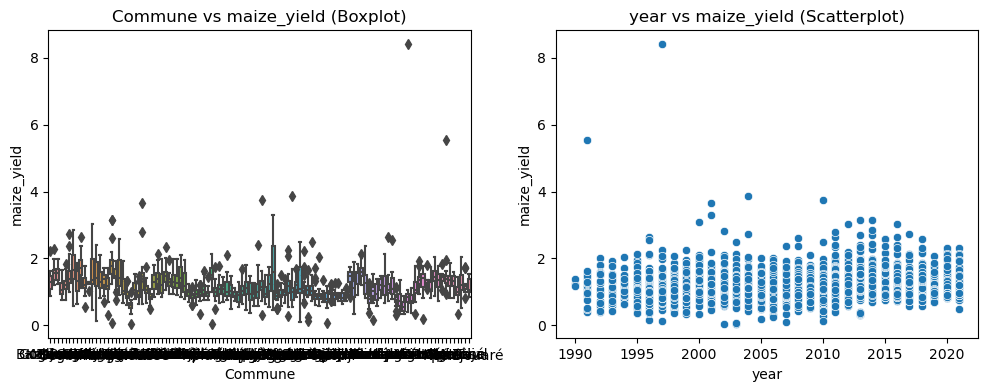

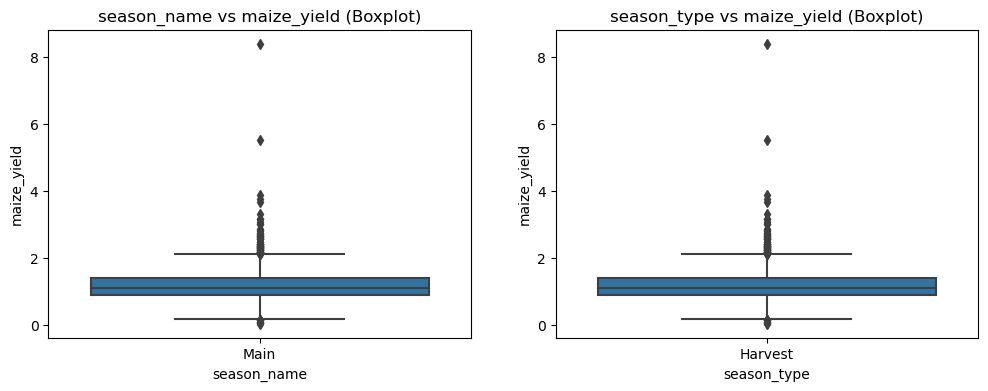

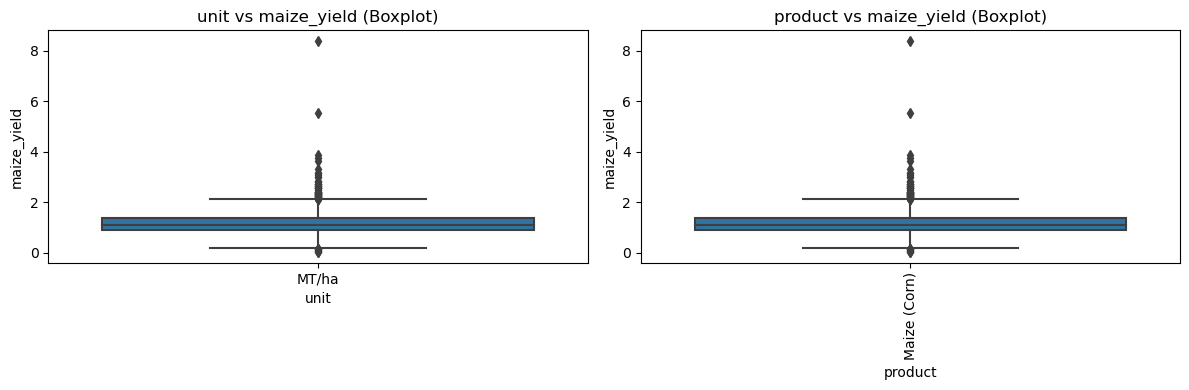

In [20]:
plot_target_vs_features(maize_data,target="maize_yield")

In [86]:

grouped_production_value=maize_data.groupby(by=["country","year"]).agg({'maize_yield': 'mean'}).reset_index()
grouped_production_value=pd.DataFrame(grouped_production_value)
togos_grouped_production_value=grouped_production_value[grouped_production_value["country"]=="Togo"]
togos_grouped_production_value=togos_grouped_production_value.rename(columns={"maize_yield":"togo_product_value"})
benins_grouped_production_value=grouped_production_value[grouped_production_value["country"]=="Benin"]
benins_grouped_production_value=benins_grouped_production_value.rename(columns={"maize_yield":"benin_product_value"})
grouped_production_value=togos_grouped_production_value.merge(benins_grouped_production_value,on="year")
grouped_production_value=grouped_production_value[["year","togo_product_value","benin_product_value"]]
grouped_production_value["date"]=pd.to_datetime(grouped_production_value["year"],format="%Y")
# grouped_production_value.set_index("date",inplace=True)


In [87]:
#grouped_production_value=maize_data.groupby(by=["country","year"]).agg({'value': 'sum'}).reset_index()
#grouped_production_value=grouped_production_value.pivot_table(values="value",columns="country",index="year",aggfunc="first",dropna=True)
#grouped_production_value=grouped_production_value.reset_index()

In [88]:
print(grouped_production_value.head())

   year  togo_product_value  benin_product_value       date
0  1995            1.083000             1.068601 1995-01-01
1  1996            1.139524             1.026812 1996-01-01
2  1997            1.223548             1.084083 1997-01-01
3  1998            1.070000             1.099009 1998-01-01
4  1999            0.975000             1.151292 1999-01-01


In [90]:
fig = px.line(
 data_frame=grouped_production_value,
 x="date",
 y=["togo_product_value","benin_product_value"],
 title="Comparison of annual producton of corn for Togo and Benin",
 labels={
   "date":"Year of the crop",
 "togo_product_value": "Togo's corn production (MT/ha)",
 "benin_product_value": "Benin's corn production (MT/ha)"
  }
)
fig=fig.update_layout(yaxis={"title":"Average annual Maize yield Production (MT/ha)"})
fig=fig.update_xaxes(rangeslider_visible=True)
fig.show()
#Save the graph in directory @figures
fig.write_image(
    os.path.join(output_dir, "1.2.png"),
    width=1000,
    height=600,
    scale=2
)


 ## 3. Administrative boundary joint data for Togo and Benin

In [25]:
#-------------------------------Administrative boundary joint data for Togo and Benin

modis_data=xr.open_dataset("data/modis_vegetation_indices/modis_vi.nc", engine="netcdf4",mask_and_scale=False)
#We set mask_and_scale=False because when bulding the modis_data, we notice that the variables values do no line in interval [-1,1]
#We are going then to get the missing value imputer and the scale value for each variable

In [26]:
print(modis_data.head())

<xarray.Dataset>
Dimensions:      (time: 5, band: 1, x: 5, y: 5)
Coordinates:
  * time         (time) datetime64[ns] 2002-07-01 2002-08-01 ... 2002-11-01
  * band         (band) int64 1
  * x            (x) float64 -0.125 -0.075 -0.025 0.025 0.075
  * y            (y) float64 12.42 12.37 12.32 12.27 12.22
Data variables:
    spatial_ref  int64 ...
    NDVI         (time, band, y, x) int16 ...
    EVI          (time, band, y, x) int16 ...
Attributes: (12/177)
    ALGORITHMPACKAGEACCEPTANCEDATE:      102004
    ALGORITHMPACKAGEMATURITYCODE:        Normal
    ALGORITHMPACKAGENAME:                MOD_PR13C2
    ALGORITHMPACKAGEVERSION:             5
    ASSOCIATEDINSTRUMENTSHORTNAME.1:     MODIS
    ASSOCIATEDPLATFORMSHORTNAME.1:       Aqua
    ...                                  ...
    SNOWICEFLAGGED:                      YES
    SOUTHBOUNDINGCOORDINATE:             -90.0
    SPSOPARAMETERS:                      2749, 4334, 2749a, 4334a
    VERSIONID:                           61
    WE

In [27]:
for variable in ["NDVI", "EVI","band"]:
    print(variable)
    print(modis_data[variable].attrs)

NDVI
{'_FillValue': -3000, 'add_offset': 0.0, 'add_offset_err': 0, 'calibrated_nt': 5, 'long_name': 'CMG 0.05 Deg Monthly NDVI', 'scale_factor': 10000.0, 'scale_factor_err': 0, 'units': 'NDVI', 'valid_range': '-2000, 10000', 'grid_mapping': 'spatial_ref'}
EVI
{'_FillValue': -3000, 'add_offset': 0.0, 'add_offset_err': 0, 'calibrated_nt': 5, 'long_name': 'CMG 0.05 Deg Monthly EVI', 'scale_factor': 10000.0, 'scale_factor_err': 0, 'units': 'EVI', 'valid_range': '-2000, 10000', 'grid_mapping': 'spatial_ref'}
band
{}


In [28]:
# Extract DataArrays and remove the singleton band dimension
NDVI = modis_data["NDVI"].squeeze("band")
EVI = modis_data["EVI"].squeeze("band")

print(NDVI.shape)  
print(EVI.shape)   

(264, 127, 81)
(264, 127, 81)


In [29]:
NDVI.attrs["_FillValue"]

-3000

In [30]:
NDVI.time.to_numpy()

array(['2002-07-01T00:00:00.000000000', '2002-08-01T00:00:00.000000000',
       '2002-09-01T00:00:00.000000000', '2002-10-01T00:00:00.000000000',
       '2002-11-01T00:00:00.000000000', '2002-12-01T00:00:00.000000000',
       '2003-01-01T00:00:00.000000000', '2003-02-01T00:00:00.000000000',
       '2003-03-01T00:00:00.000000000', '2003-04-01T00:00:00.000000000',
       '2003-05-01T00:00:00.000000000', '2003-06-01T00:00:00.000000000',
       '2003-07-01T00:00:00.000000000', '2003-08-01T00:00:00.000000000',
       '2003-09-01T00:00:00.000000000', '2003-10-01T00:00:00.000000000',
       '2003-11-01T00:00:00.000000000', '2003-12-01T00:00:00.000000000',
       '2004-01-01T00:00:00.000000000', '2004-02-01T00:00:00.000000000',
       '2004-03-01T00:00:00.000000000', '2004-04-01T00:00:00.000000000',
       '2004-05-01T00:00:00.000000000', '2004-06-01T00:00:00.000000000',
       '2004-07-01T00:00:00.000000000', '2004-08-01T00:00:00.000000000',
       '2004-09-01T00:00:00.000000000', '2004-10-01

In [31]:
#modis_data converted as a dataframe
modis_data_df = (
    modis_data[["NDVI", "EVI"]]
    .squeeze("band")
    .to_dataframe()
    .reset_index()
)

print(modis_data_df.head(20))

         time       y      x  NDVI   EVI  band
0  2002-07-01  12.425 -0.125  2656  1769     1
1  2002-07-01  12.425 -0.075  2926  2047     1
2  2002-07-01  12.425 -0.025  2734  1958     1
3  2002-07-01  12.425  0.025  2434  1765     1
4  2002-07-01  12.425  0.075  3201  2352     1
5  2002-07-01  12.425  0.125  3418  2483     1
6  2002-07-01  12.425  0.175  3231  2272     1
7  2002-07-01  12.425  0.225  3253  2292     1
8  2002-07-01  12.425  0.275  3891  2728     1
9  2002-07-01  12.425  0.325  3656  2583     1
10 2002-07-01  12.425  0.375  3458  2486     1
11 2002-07-01  12.425  0.425  3542  2545     1
12 2002-07-01  12.425  0.475  3665  2649     1
13 2002-07-01  12.425  0.525  3815  2763     1
14 2002-07-01  12.425  0.575  4057  2888     1
15 2002-07-01  12.425  0.625  3743  2569     1
16 2002-07-01  12.425  0.675  4086  2836     1
17 2002-07-01  12.425  0.725  3586  2173     1
18 2002-07-01  12.425  0.775  3248  2176     1
19 2002-07-01  12.425  0.825  3657  2371     1


In [32]:
#Replace NA values and scale the variable
def process_modis_data(ds, variable):

    da = ds[variable]

    fill_value = da.attrs["_FillValue"]
    scale_factor = da.attrs["scale_factor"]

    # Metadata valid_range is a string in this file
    valid_min, valid_max = map(
        float,
        da.attrs["valid_range"].split(",")
    )

    # Replace fill values and invalid observations with NaN
    da = da.where(
        (da != fill_value)
        & (da >= valid_min)
        & (da <= valid_max),
        other=np.nan
    )

    # Convert raw MODIS integers to physical VI values
    da = da / scale_factor

    return da


modis_data["NDVI"]= process_modis_data(modis_data, "NDVI")
modis_data["EVI"] = process_modis_data(modis_data, "EVI")

In [33]:
#modis_data converted as a dataframe with scaled variable
modis_data_df = (
    modis_data[["NDVI", "EVI"]]
    .squeeze("band")
    .to_dataframe()
    .reset_index()
)

print(modis_data_df.head(20))

         time       y      x    NDVI     EVI  band
0  2002-07-01  12.425 -0.125  0.2656  0.1769     1
1  2002-07-01  12.425 -0.075  0.2926  0.2047     1
2  2002-07-01  12.425 -0.025  0.2734  0.1958     1
3  2002-07-01  12.425  0.025  0.2434  0.1765     1
4  2002-07-01  12.425  0.075  0.3201  0.2352     1
5  2002-07-01  12.425  0.125  0.3418  0.2483     1
6  2002-07-01  12.425  0.175  0.3231  0.2272     1
7  2002-07-01  12.425  0.225  0.3253  0.2292     1
8  2002-07-01  12.425  0.275  0.3891  0.2728     1
9  2002-07-01  12.425  0.325  0.3656  0.2583     1
10 2002-07-01  12.425  0.375  0.3458  0.2486     1
11 2002-07-01  12.425  0.425  0.3542  0.2545     1
12 2002-07-01  12.425  0.475  0.3665  0.2649     1
13 2002-07-01  12.425  0.525  0.3815  0.2763     1
14 2002-07-01  12.425  0.575  0.4057  0.2888     1
15 2002-07-01  12.425  0.625  0.3743  0.2569     1
16 2002-07-01  12.425  0.675  0.4086  0.2836     1
17 2002-07-01  12.425  0.725  0.3586  0.2173     1
18 2002-07-01  12.425  0.775  0

In [34]:
modis_data_df["year"]=pd.to_datetime(modis_data_df["time"]).dt.year
modis_data_df["month"]=pd.to_datetime(modis_data_df["time"]).dt.month

In [35]:
print(modis_data_df.head())

        time       y      x    NDVI     EVI  band  year  month
0 2002-07-01  12.425 -0.125  0.2656  0.1769     1  2002      7
1 2002-07-01  12.425 -0.075  0.2926  0.2047     1  2002      7
2 2002-07-01  12.425 -0.025  0.2734  0.1958     1  2002      7
3 2002-07-01  12.425  0.025  0.2434  0.1765     1  2002      7
4 2002-07-01  12.425  0.075  0.3201  0.2352     1  2002      7


In [36]:
# Convert modis_data_df to GeoDataFrame
modis_data_gdf = gpd.GeoDataFrame(
    modis_data_df,
    geometry=gpd.points_from_xy(
        modis_data_df["x"],
        modis_data_df["y"]
    ),
    crs="EPSG:4326"
)

In [37]:
print(modis_data_gdf.head())

        time       y      x    NDVI     EVI  band  year  month  \
0 2002-07-01  12.425 -0.125  0.2656  0.1769     1  2002      7   
1 2002-07-01  12.425 -0.075  0.2926  0.2047     1  2002      7   
2 2002-07-01  12.425 -0.025  0.2734  0.1958     1  2002      7   
3 2002-07-01  12.425  0.025  0.2434  0.1765     1  2002      7   
4 2002-07-01  12.425  0.075  0.3201  0.2352     1  2002      7   

                geometry  
0  POINT (-0.125 12.425)  
1  POINT (-0.075 12.425)  
2  POINT (-0.025 12.425)  
3   POINT (0.025 12.425)  
4   POINT (0.075 12.425)  


In [38]:
modis_data_gdf.shape

(2715768, 9)

In [39]:
# Spatial join of modis data and togo_benin boundary data
modis_togo_benin_geo_data = gpd.sjoin(
    modis_data_gdf,
    togo_benin_geo_data[["Country", "Region", "Commune", "geometry"]],
    how="inner",
    predicate="within"
)

In [40]:
print(modis_togo_benin_geo_data.head())

          time       y      x    NDVI     EVI  band  year  month  \
139 2002-07-01  12.375  2.775  0.5306  0.3788     1  2002      7   
140 2002-07-01  12.375  2.825  0.4097  0.2900     1  2002      7   
141 2002-07-01  12.375  2.875  0.3418  0.2399     1  2002      7   
219 2002-07-01  12.325  2.725  0.4815  0.3176     1  2002      7   
220 2002-07-01  12.325  2.775  0.4850  0.3277     1  2002      7   

                 geometry  index_right Country   Region   Commune  
139  POINT (2.775 12.375)            3   Benin  Alibori  Karimama  
140  POINT (2.825 12.375)            3   Benin  Alibori  Karimama  
141  POINT (2.875 12.375)            3   Benin  Alibori  Karimama  
219  POINT (2.725 12.325)            3   Benin  Alibori  Karimama  
220  POINT (2.775 12.325)            3   Benin  Alibori  Karimama  


In [41]:
modis_data_df_stats = (
    modis_togo_benin_geo_data
    .groupby(["Country", "Region", "Commune","year", "month"])
    .agg(
        NDVI_min=("NDVI", "min"),
        NDVI_mean=("NDVI", "mean"),
        NDVI_max=("NDVI", "max"),
        EVI_min=("EVI", "min"),
        EVI_mean=("EVI", "mean"),
        EVI_max=("EVI", "max")
    )
    .reset_index()
)

print(modis_data_df_stats.head())

  Country   Region    Commune  year  month  NDVI_min  NDVI_mean  NDVI_max  \
0   Benin  Alibori  Banikoara  2002      7    0.3668   0.556722    0.7109   
1   Benin  Alibori  Banikoara  2002      8    0.5818   0.721632    0.7814   
2   Benin  Alibori  Banikoara  2002      9    0.6626   0.715412    0.7749   
3   Benin  Alibori  Banikoara  2002     10    0.5758   0.649849    0.6991   
4   Benin  Alibori  Banikoara  2002     11    0.3799   0.475988    0.5415   

   EVI_min  EVI_mean  EVI_max  
0   0.2526  0.378289   0.4703  
1   0.3877  0.501901   0.5723  
2   0.4557  0.505632   0.5645  
3   0.3775  0.433699   0.4880  
4   0.2112  0.272231   0.3210  


In [42]:
# Attach administrative polygon geometry
modis_data_df_stats = modis_data_df_stats.merge(
    togo_benin_geo_data[
        ["Country", "Region", "Commune", "geometry"]
    ],
    on=["Country", "Region", "Commune"],
    how="left"
)
modis_data_df_stats.drop_duplicates(inplace=True)

In [43]:
modis_data_df_stats

,Country,Region,Commune,year,month,NDVI_min,NDVI_mean,NDVI_max,EVI_min,EVI_mean,EVI_max,geometry
0,Benin,Alibori,Banikoara,2002,7,0.3668,0.556722,0.7109,0.2526,0.378289,0.4703,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."
1,Benin,Alibori,Banikoara,2002,8,0.5818,0.721632,0.7814,0.3877,0.501901,0.5723,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."
2,Benin,Alibori,Banikoara,2002,9,0.6626,0.715412,0.7749,0.4557,0.505632,0.5645,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."
3,Benin,Alibori,Banikoara,2002,10,0.5758,0.649849,0.6991,0.3775,0.433699,0.4880,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."
4,Benin,Alibori,Banikoara,2002,11,0.3799,0.475988,0.5415,0.2112,0.272231,0.3210,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."
...,...,...,...,...,...,...,...,...,...,...,...,...
31147,Togo,Savanes,Tône,2024,2,0.2147,0.233327,0.2581,0.1402,0.153614,0.1709,"MULTIPOLYGON (((0.3329 10.7037, 0.3346 10.6961..."
31148,Togo,Savanes,Tône,2024,3,0.2152,0.234149,0.2672,0.1445,0.160422,0.1756,"MULTIPOLYGON (((0.3329 10.7037, 0.3346 10.6961..."
31149,Togo,Savanes,Tône,2024,4,0.2154,0.234981,0.2692,0.1453,0.158795,0.1806,"MULTIPOLYGON (((0.3329 10.7037, 0.3346 10.6961..."
31150,Togo,Savanes,Tône,2024,5,0.2142,0.232465,0.2735,0.1345,0.149462,0.1692,"MULTIPOLYGON (((0.3329 10.7037, 0.3346 10.6961..."


In [44]:
# Convert back to GeoDataFrame
modis_data_stats_geodf = gpd.GeoDataFrame(
    modis_data_df_stats,
    geometry="geometry",
    crs=togo_benin_geo_data.crs
)

In [45]:
modis_data_stats_geodf.shape

(31152, 12)

## Plot of NDVI_mean for district or commune

In [46]:
#Plot of district or commune
# Select a vegetation index for a year and a month
vegetation_index = "NDVI_mean"
year = 2002
month = 7

subset_modis_data_stats_geodf = modis_data_stats_geodf[
    (modis_data_stats_geodf["year"] == year) &
    (modis_data_stats_geodf["month"] == month)
]
subset_modis_data_stats_geodf.shape

(118, 12)

In [49]:
commune_geojson = json.loads(subset_modis_data_stats_geodf[["Commune", "geometry"]].to_json())
fig_commune=px.choropleth_map(
    data_frame=subset_modis_data_stats_geodf,
    geojson=commune_geojson,
    locations="Commune",
    featureidkey="properties.Commune",
    color="NDVI_mean",
    color_continuous_scale="RdYlGn",
    range_color=(-0.2, 1),
    hover_name="Commune",
    center={"lat": 8.3, "lon": 1.1}, #centered around Togo and Benin
    zoom=5,
    map_style="basic"
)
fig_commune=fig_commune.update_traces(marker=dict(line=dict(color="white",width=0.4)))
fig_commune.show()

In [50]:
#Save the graph
fig_commune.write_image(os.path.join(output_dir, "1.3.png"))

## Interpretation

It ca be observed that there is a clear identification of difference in polygons within their boundary and acrros their boundary. It is a clear identication of difference of Communes in term of maize yield.

## Plot NDVI_mean index for regions

In [51]:
#Plot of district or commune
# Select a vegetation index, year and month
vegetation_index = "NDVI_mean"
year = 2002
month = 7

subset_modis_data_stats_geodf = modis_data_stats_geodf[
    (modis_data_stats_geodf["year"] == year) &
    (modis_data_stats_geodf["month"] == month)
]
subset_modis_data_stats_geodf.shape

subset_modis_data_stats_geodf = subset_modis_data_stats_geodf.dissolve(by="Region").reset_index()
subset_modis_data_stats_geodf["Region_id"] = subset_modis_data_stats_geodf.index.astype(str)

region_geojson = json.loads(subset_modis_data_stats_geodf[["Region", "geometry"]].to_json())
fig_region=px.choropleth_map(
    data_frame=subset_modis_data_stats_geodf,
    geojson=region_geojson,
    locations="Region",
    featureidkey="properties.Region",
    color="NDVI_mean",
    color_continuous_scale="RdYlGn",
    range_color=(-0.2, 1),
    hover_name="Region",
    center={"lat": 8.3, "lon": 1.1}, #centered around Togo and Bening
    zoom=5,
    map_style="basic"
)
fig_region=fig_region.update_traces(marker=dict(line=dict(color="white",width=0.4)))
fig_region.show()

## Interpretation

It can be observed the same display for regional polygons identification in terms of NDVI_mean densification within regions. We conclude that there is no difference between regions and communes.

## 4: Extracted Data reshaping into a wide format

In [52]:
modis_data_df_stats.head()

,Country,Region,Commune,year,month,NDVI_min,NDVI_mean,NDVI_max,EVI_min,EVI_mean,EVI_max,geometry
0,Benin,Alibori,Banikoara,2002,7,0.3668,0.556722,0.7109,0.2526,0.378289,0.4703,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."
1,Benin,Alibori,Banikoara,2002,8,0.5818,0.721632,0.7814,0.3877,0.501901,0.5723,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."
2,Benin,Alibori,Banikoara,2002,9,0.6626,0.715412,0.7749,0.4557,0.505632,0.5645,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."
3,Benin,Alibori,Banikoara,2002,10,0.5758,0.649849,0.6991,0.3775,0.433699,0.4880,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."
4,Benin,Alibori,Banikoara,2002,11,0.3799,0.475988,0.5415,0.2112,0.272231,0.3210,"MULTIPOLYGON (((2.8029 11.4103, 2.8202 11.4121..."


In [53]:
vegetation_index_statts=["NDVI_min", "NDVI_mean", "NDVI_max", "EVI_min", "EVI_mean", "EVI_max"]
geo_dims=["Country","Region","Commune","year"]

In [54]:
wide_modis_data_df_stats=modis_data_df_stats.pivot_table(
    values=vegetation_index_statts,
    index=geo_dims,
    columns="month",
    aggfunc ="first",
    dropna=True
)

In [55]:
wide_modis_data_df_stats.shape

(2714, 72)

In [56]:
wide_modis_data_df_stats.columns

MultiIndex([(  'EVI_max',  1),
            (  'EVI_max',  2),
            (  'EVI_max',  3),
            (  'EVI_max',  4),
            (  'EVI_max',  5),
            (  'EVI_max',  6),
            (  'EVI_max',  7),
            (  'EVI_max',  8),
            (  'EVI_max',  9),
            (  'EVI_max', 10),
            (  'EVI_max', 11),
            (  'EVI_max', 12),
            ( 'EVI_mean',  1),
            ( 'EVI_mean',  2),
            ( 'EVI_mean',  3),
            ( 'EVI_mean',  4),
            ( 'EVI_mean',  5),
            ( 'EVI_mean',  6),
            ( 'EVI_mean',  7),
            ( 'EVI_mean',  8),
            ( 'EVI_mean',  9),
            ( 'EVI_mean', 10),
            ( 'EVI_mean', 11),
            ( 'EVI_mean', 12),
            (  'EVI_min',  1),
            (  'EVI_min',  2),
            (  'EVI_min',  3),
            (  'EVI_min',  4),
            (  'EVI_min',  5),
            (  'EVI_min',  6),
            (  'EVI_min',  7),
            (  'EVI_min',  8),
        

In [57]:
new_colums_names=[f"{var.lower()}_{month}" for var, month in wide_modis_data_df_stats.columns]

In [58]:
wide_modis_data_df_stats.columns=new_colums_names

In [59]:
wide_modis_data_df_stats.reset_index(inplace=True)

In [60]:
wide_modis_data_df_stats.head()

,Country,Region,Commune,year,evi_max_1,evi_max_2,evi_max_3,evi_max_4,evi_max_5,evi_max_6,...,ndvi_min_3,ndvi_min_4,ndvi_min_5,ndvi_min_6,ndvi_min_7,ndvi_min_8,ndvi_min_9,ndvi_min_10,ndvi_min_11,ndvi_min_12
0,Benin,Alibori,Banikoara,2002,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.3668,0.5818,0.6626,0.5758,0.3799,0.3005
1,Benin,Alibori,Banikoara,2003,0.1977,0.1892,0.1802,0.2624,0.3254,0.4521,...,0.2224,0.2473,0.2559,0.3729,0.5283,0.6533,0.6490,0.5264,0.3896,0.2682
2,Benin,Alibori,Banikoara,2004,0.1950,0.1762,0.1731,0.2502,0.3164,0.4008,...,0.2120,0.2195,0.2602,0.3647,0.4283,0.5687,0.6629,0.5458,0.3602,0.2450
3,Benin,Alibori,Banikoara,2005,0.1855,0.1675,0.1737,0.2224,0.3294,0.4199,...,0.1862,0.2281,0.2584,0.3001,0.4407,0.4269,0.6391,0.5849,0.3689,0.2715
4,Benin,Alibori,Banikoara,2006,0.1912,0.1817,0.1877,0.2152,0.2462,0.3732,...,0.2253,0.2207,0.2436,0.2554,0.3020,0.5536,0.6576,0.6271,0.4379,0.2989


## Merger with maize data

In [61]:
maize_data_new=maize_data.rename(columns={"country":"Country"})

In [62]:
wide_modis_data_df_stats=wide_modis_data_df_stats.merge(maize_data_new,on=geo_dims)

In [63]:
print(wide_modis_data_df_stats.head())

  Country   Region    Commune  year  evi_max_1  evi_max_2  evi_max_3  \
0   Benin  Alibori  Banikoara  2002        NaN        NaN        NaN   
1   Benin  Alibori  Banikoara  2003     0.1977     0.1892     0.1802   
2   Benin  Alibori  Banikoara  2004     0.1950     0.1762     0.1731   
3   Benin  Alibori  Banikoara  2005     0.1855     0.1675     0.1737   
4   Benin  Alibori  Banikoara  2006     0.1912     0.1817     0.1877   

   evi_max_4  evi_max_5  evi_max_6  ...  ndvi_min_8  ndvi_min_9  ndvi_min_10  \
0        NaN        NaN        NaN  ...      0.5818      0.6626       0.5758   
1     0.2624     0.3254     0.4521  ...      0.6533      0.6490       0.5264   
2     0.2502     0.3164     0.4008  ...      0.5687      0.6629       0.5458   
3     0.2224     0.3294     0.4199  ...      0.4269      0.6391       0.5849   
4     0.2152     0.2462     0.3732  ...      0.5536      0.6576       0.6271   

   ndvi_min_11  ndvi_min_12  season_name  season_type  maize_yield   unit  \
0       0

# Task 2: Modeling and results interpretation

In [64]:
def plot_hist(df,target,bins=50):
    # Matplotlib
    plt.hist(df[target], bins=bins, color='skyblue', edgecolor='white')
    plt.title(f"Histogram of {target}")
    plt.xlabel(f"{target}")
    plt.ylabel("Frequency")
    plt.show()

def sklearn_model_hex(df, ratios=[.8,.2], seed = 1):
  df_skl_train_hex, df_skl_test_hex = train_test_split(df,train_size=ratios[0],test_size=ratios[1],random_state=seed)
  return(df_skl_train_hex,df_skl_test_hex)

In [65]:
maize_data_new["log_maize_yield"]=maize_data_new["maize_yield"].apply(lambda x: mathlog(x))

## 1: Distribution comparison

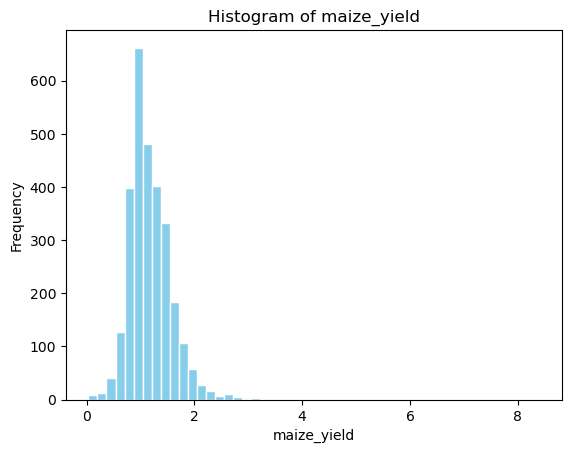

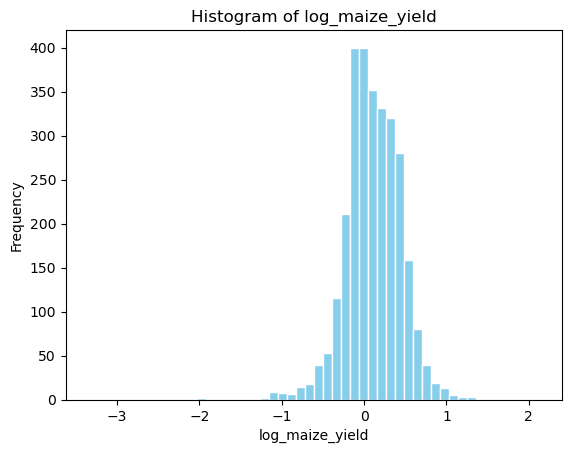

In [66]:
plot_hist(maize_data_new,target="maize_yield")
plot_hist(maize_data_new,target="log_maize_yield")

I prefer using the yield value for modeling instead of using its log transformation.  Yield value is more normal distributed than its log transformation which tends to display a heavy tail values which could be difficult to predict if there is no appropriate statistical distribution that can fit them.

## 2: Modeling

In [67]:
wide_modis_data_df_stats["Commune"]=wide_modis_data_df_stats["Commune"].astype("category")
wide_modis_data_df_stats["Region"]=wide_modis_data_df_stats["Region"].astype("category")
wide_modis_data_df_stats["Country"]=wide_modis_data_df_stats["Country"].astype("category")

In [68]:
wide_modis_data_df_stats.shape

(1997, 81)

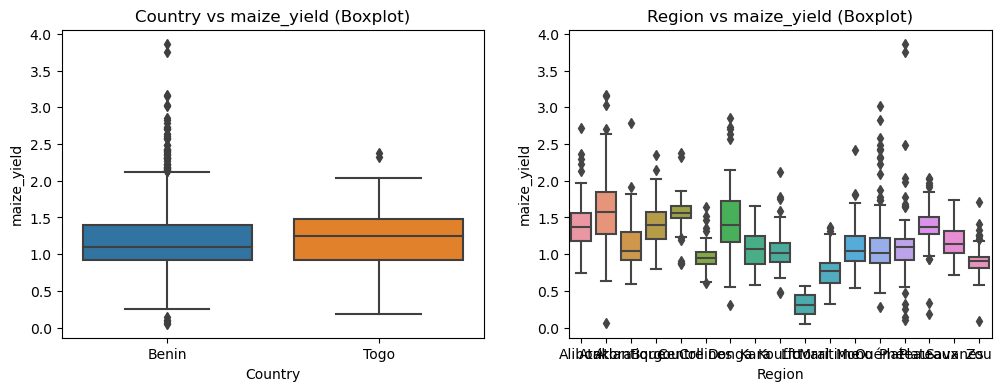

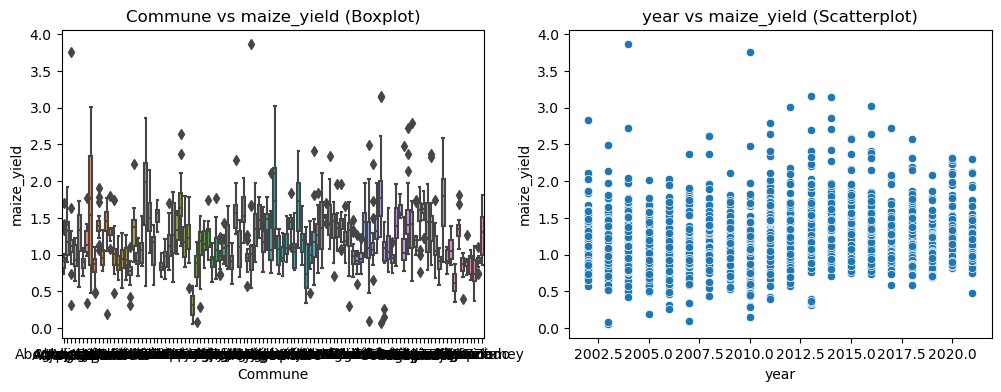

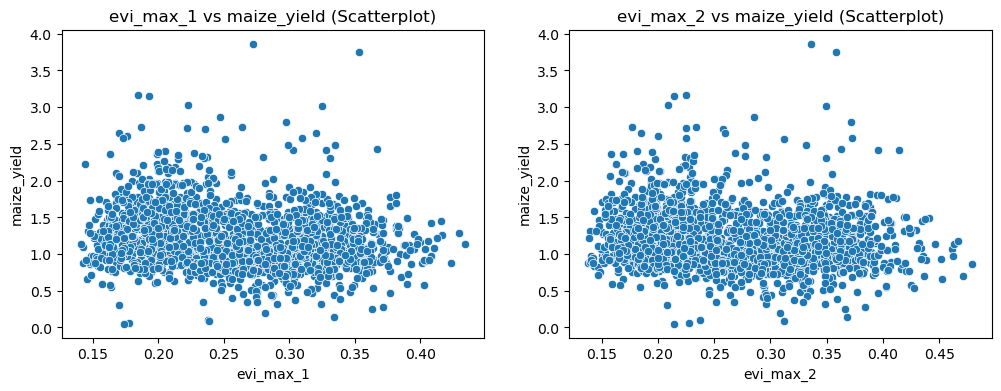

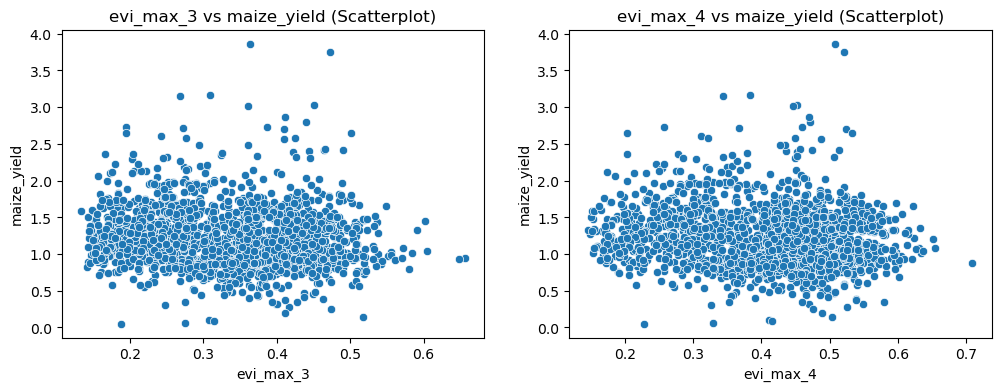

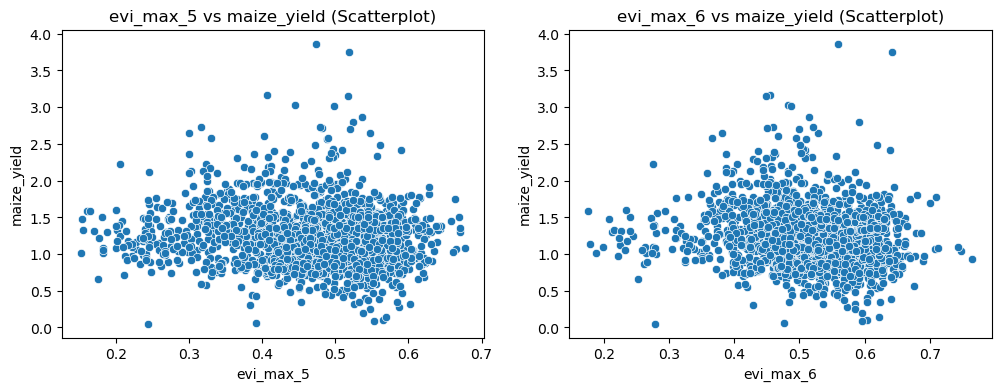

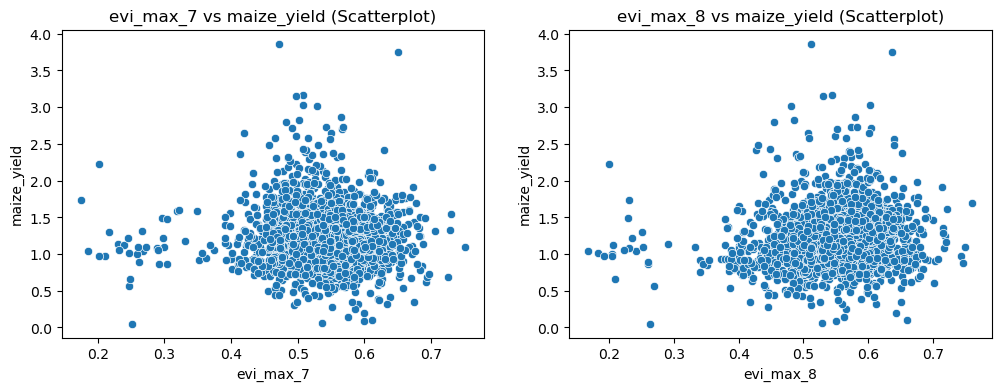

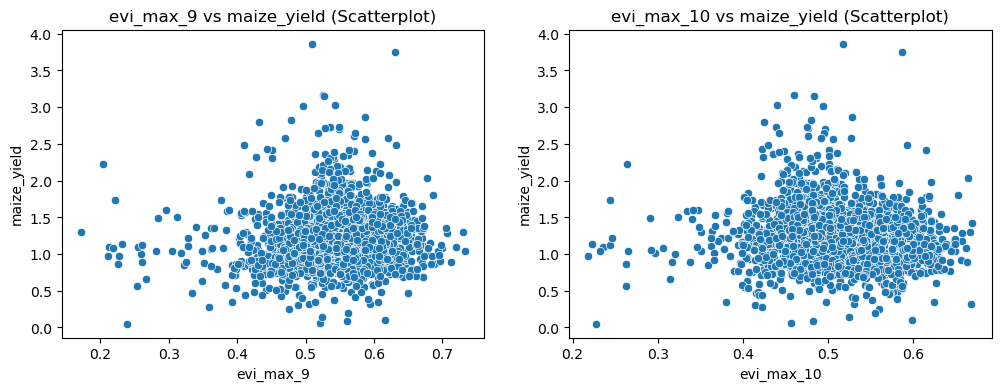

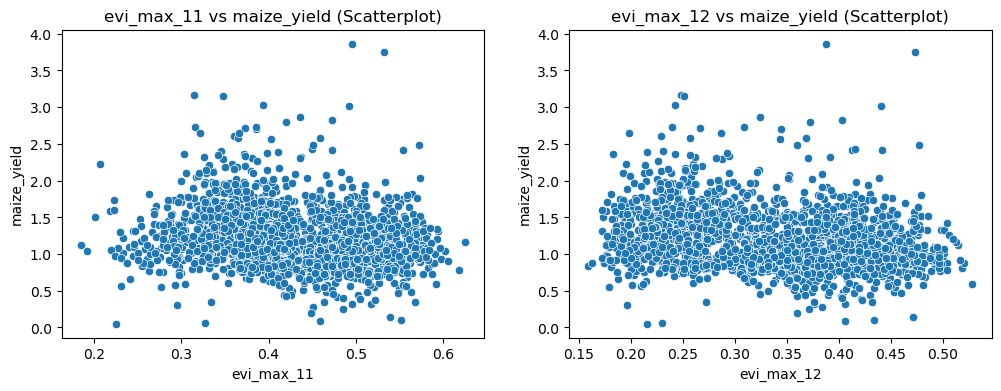

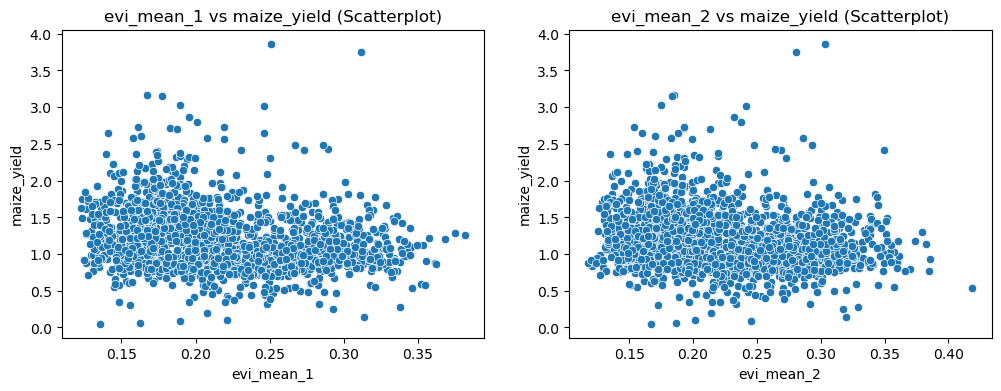

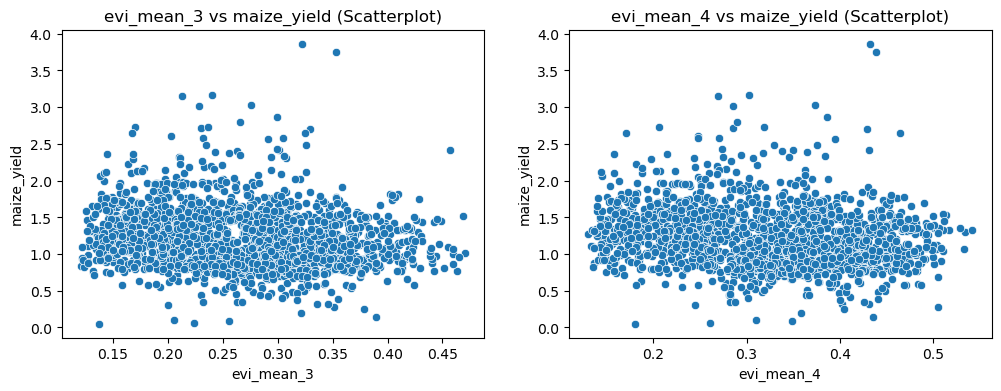

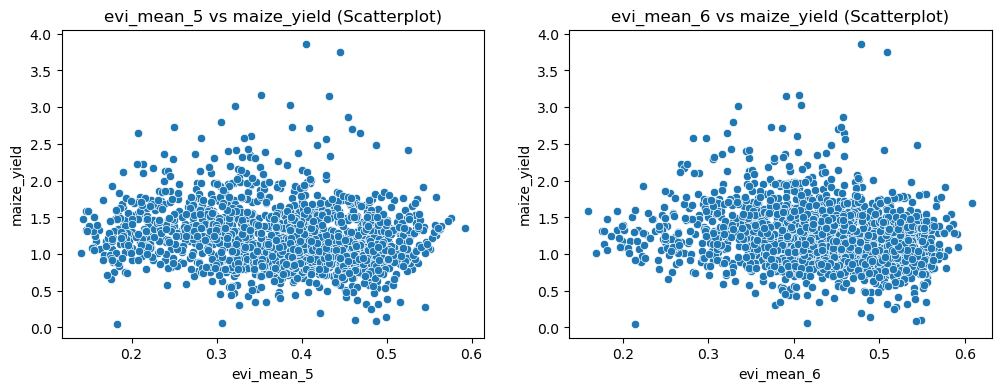

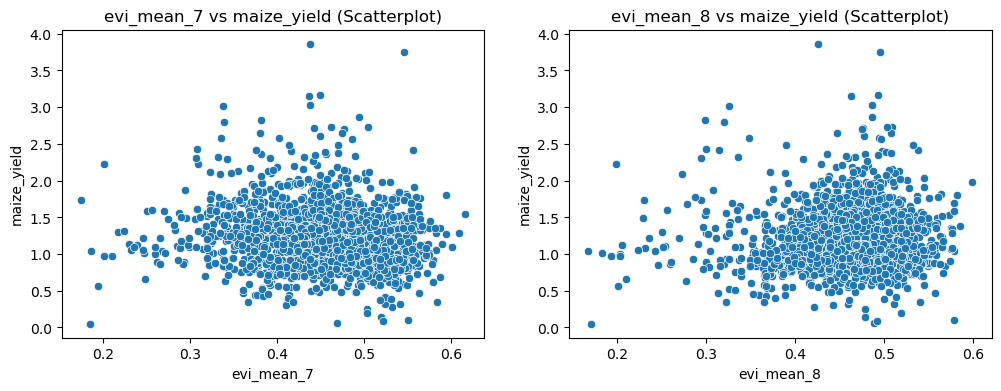

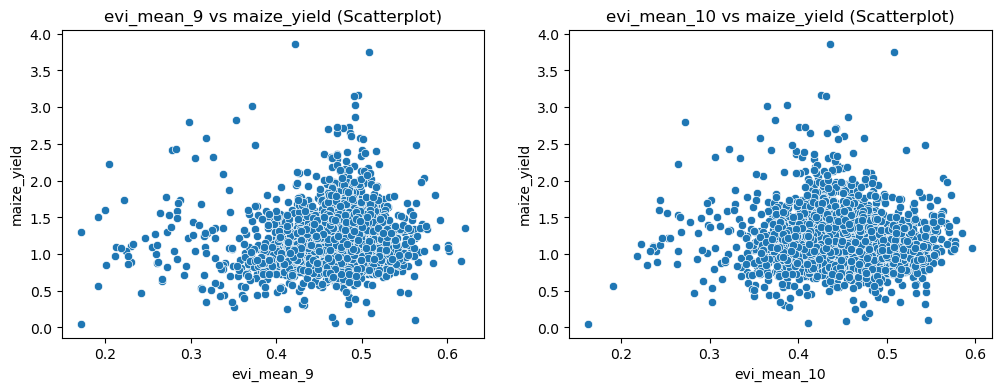

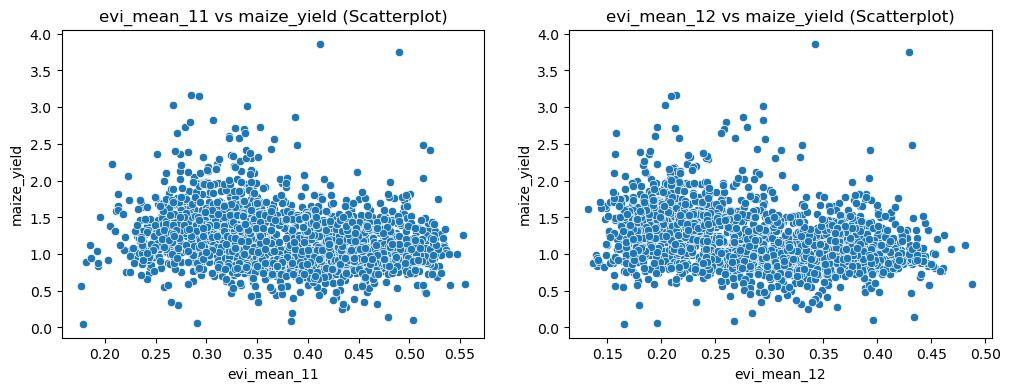

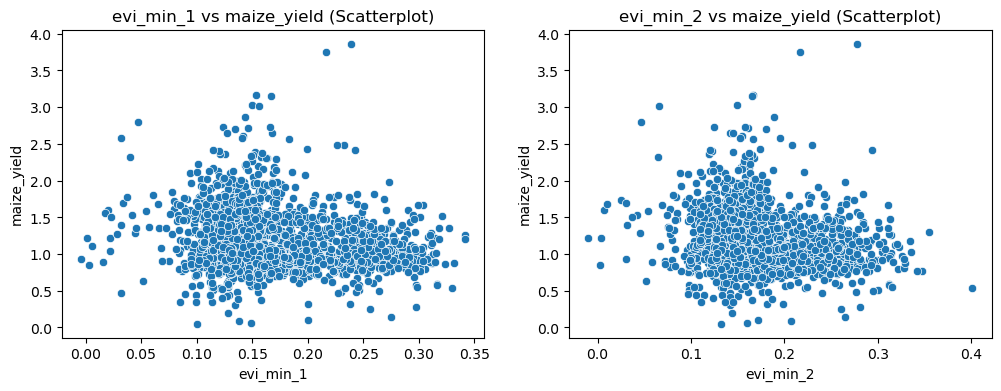

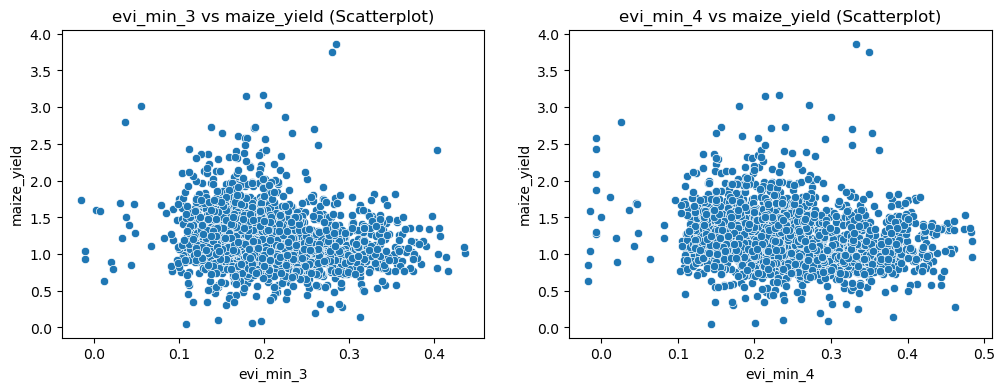

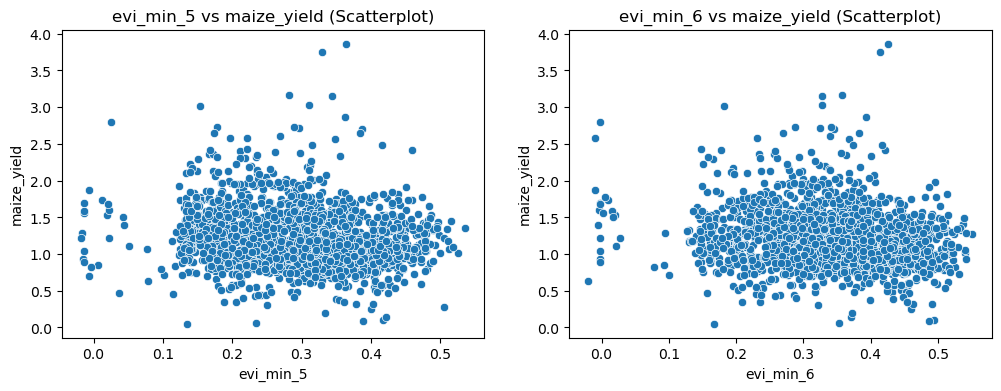

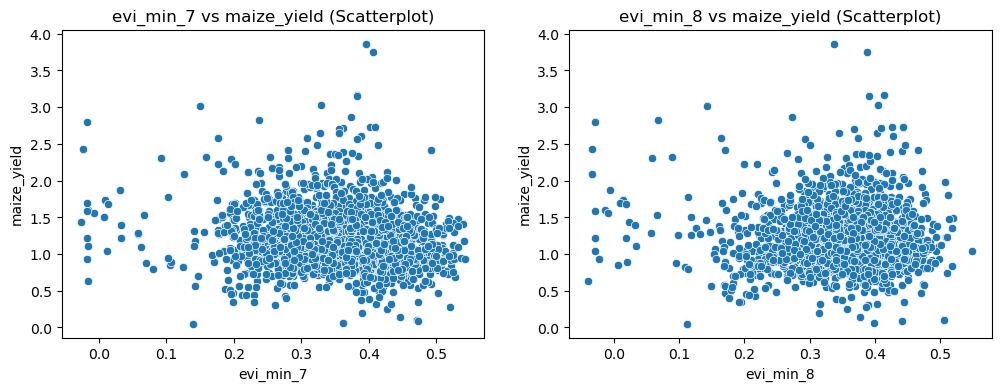

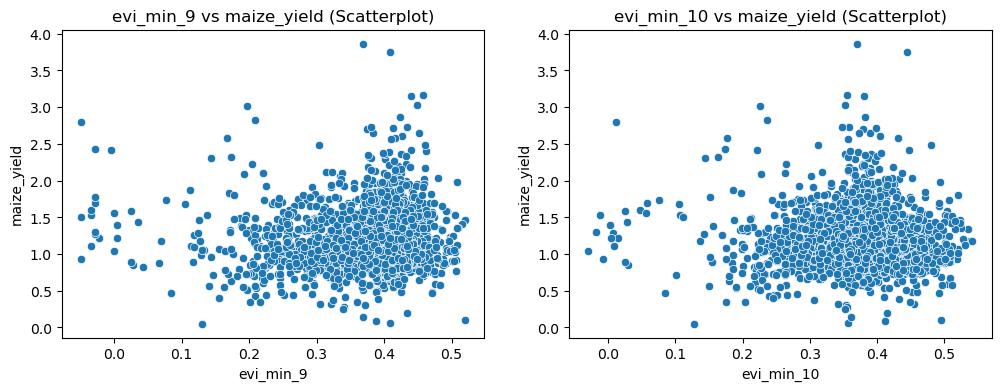

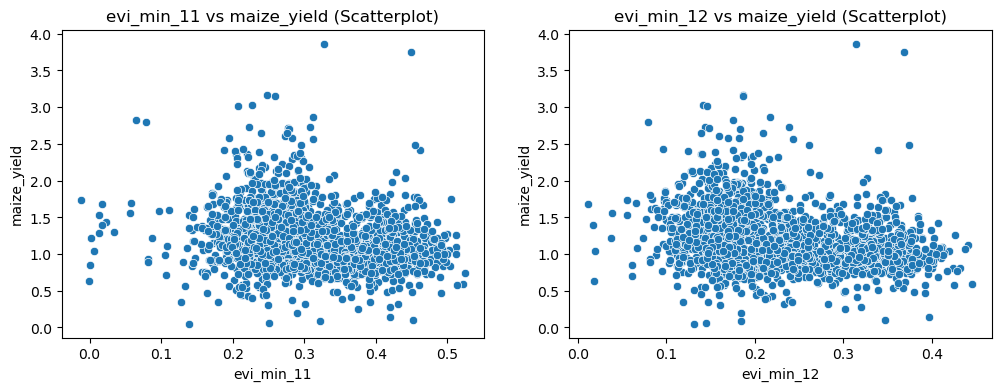

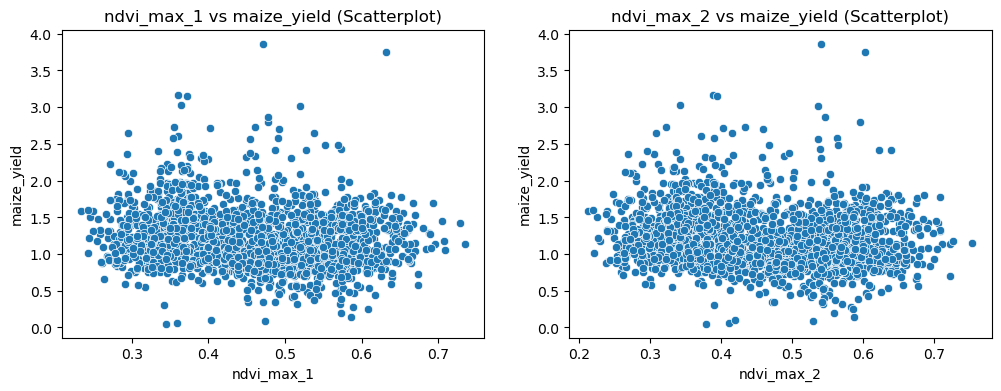

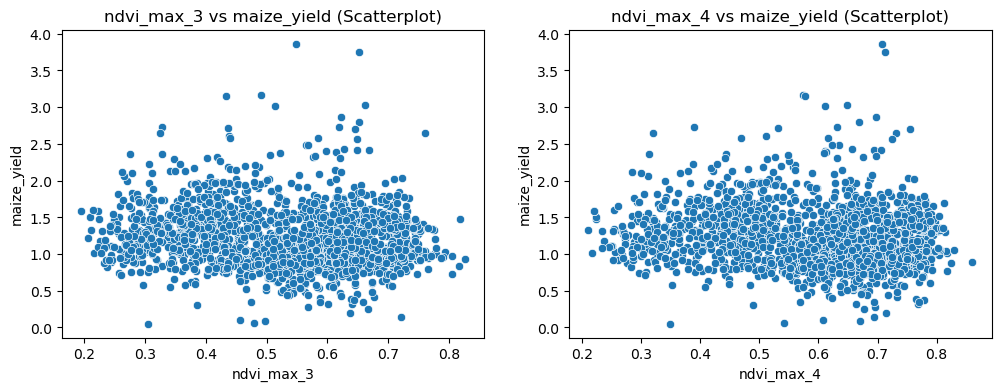

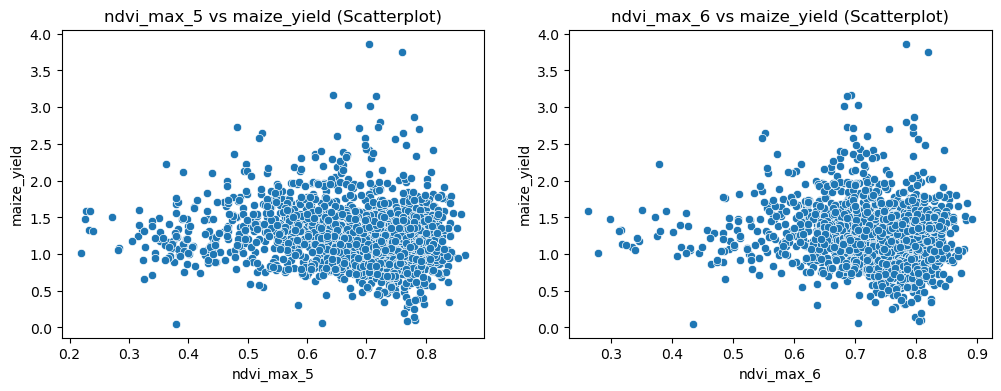

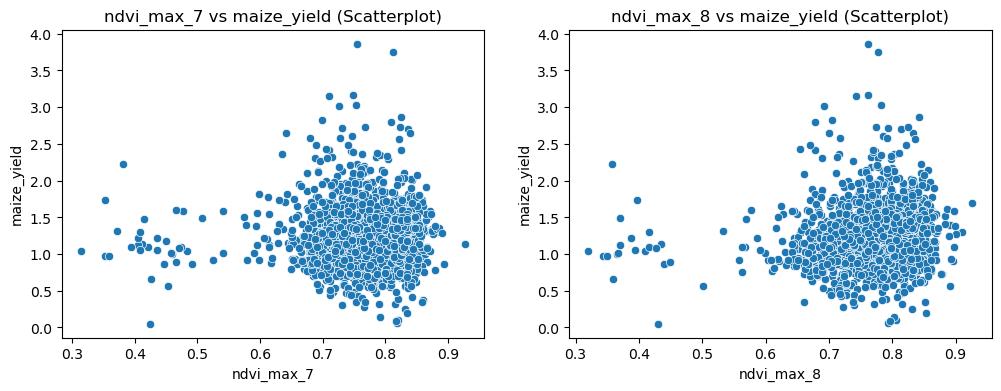

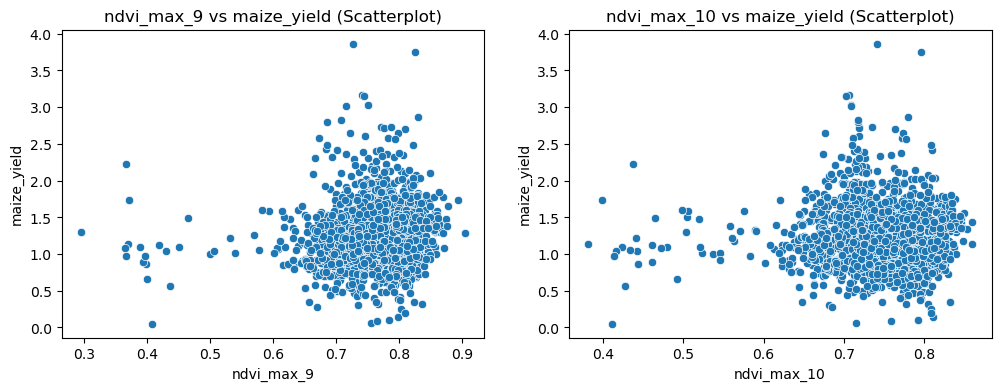

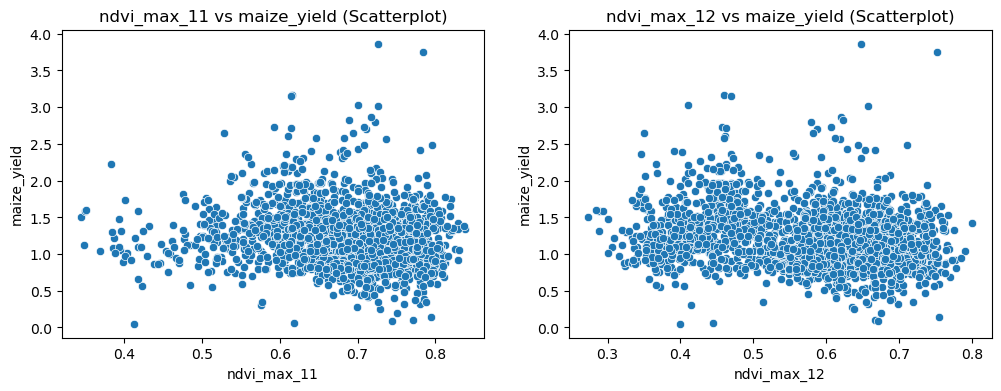

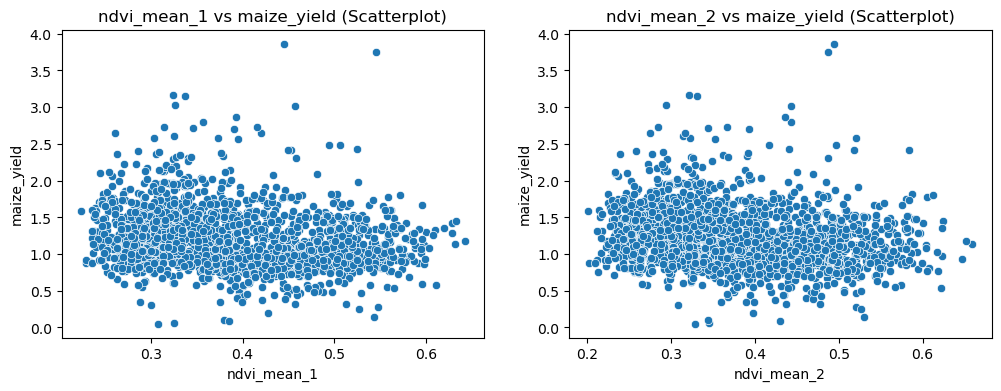

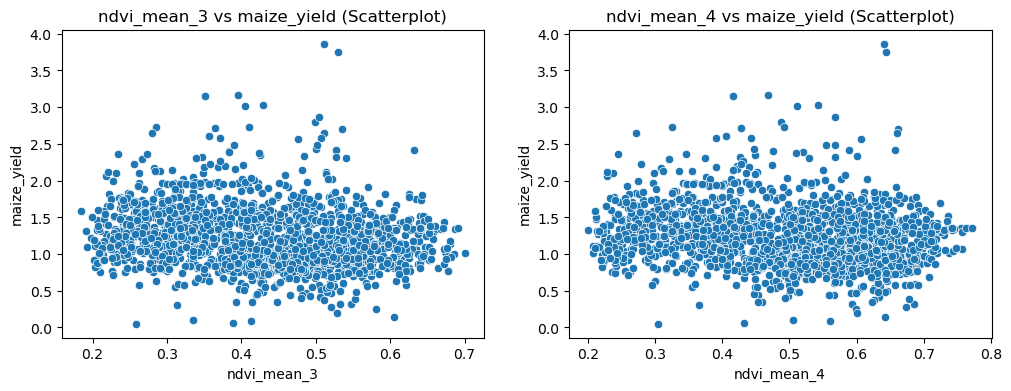

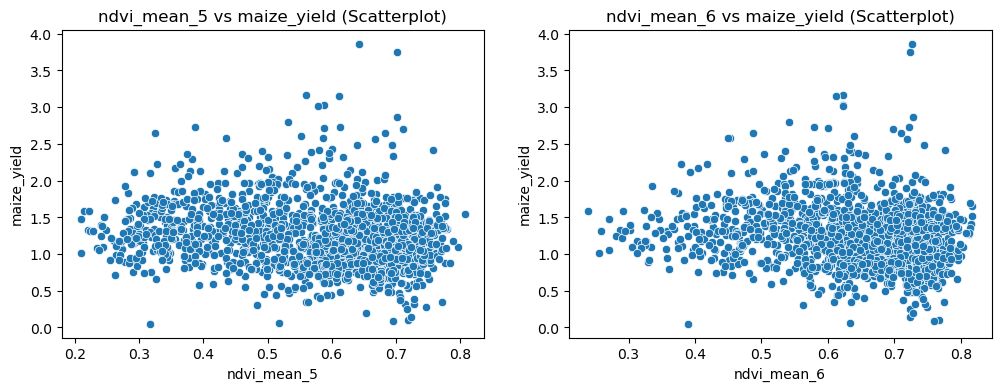

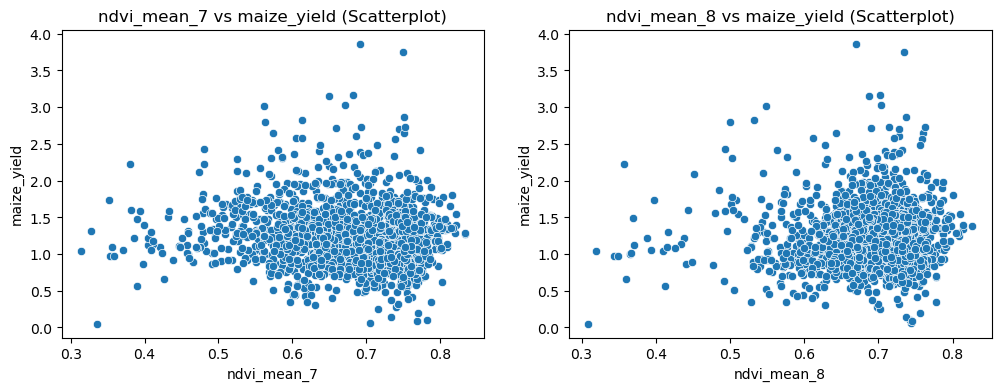

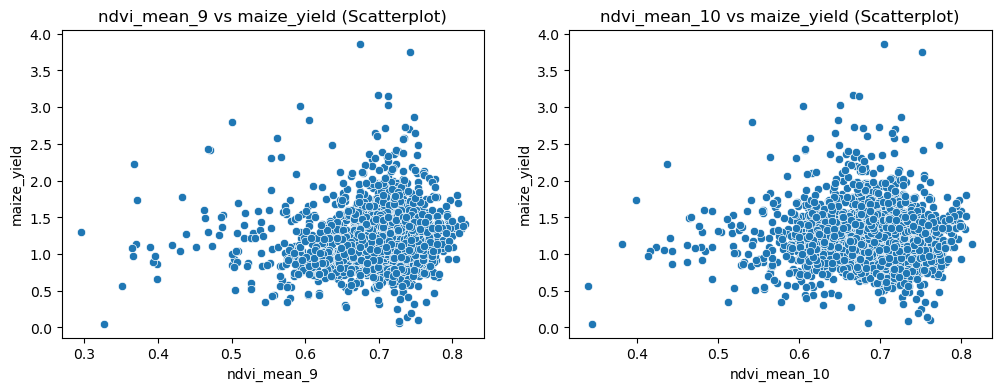

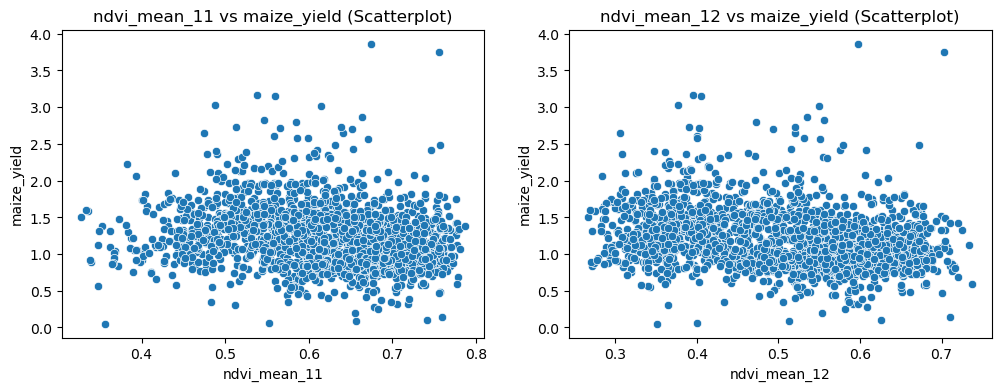

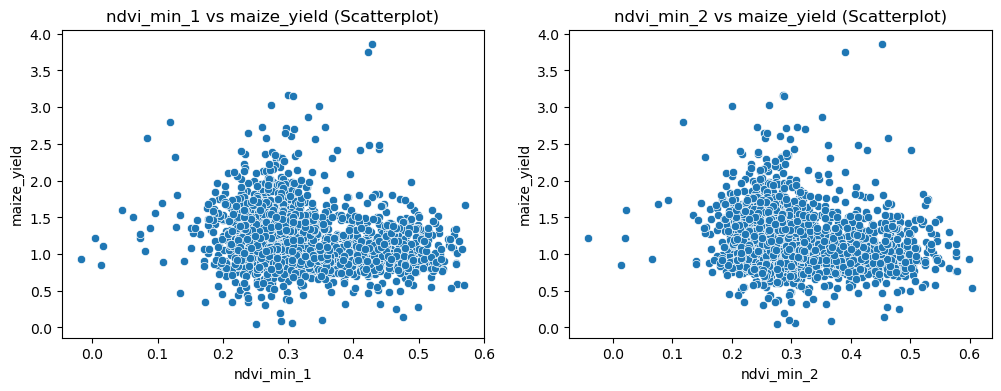

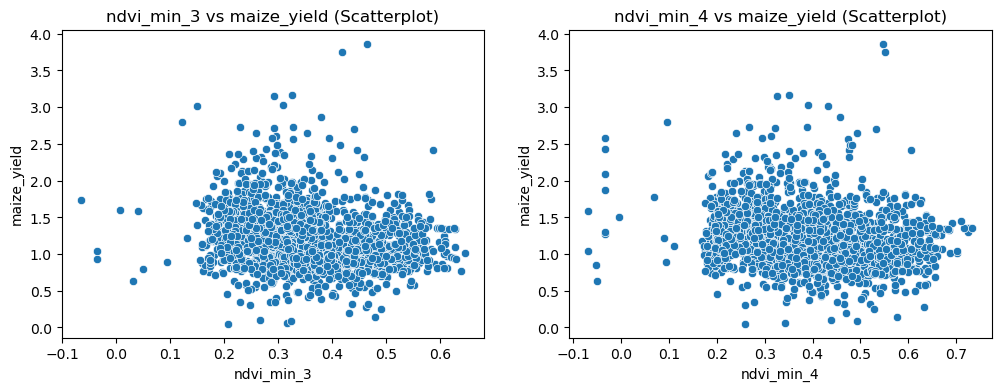

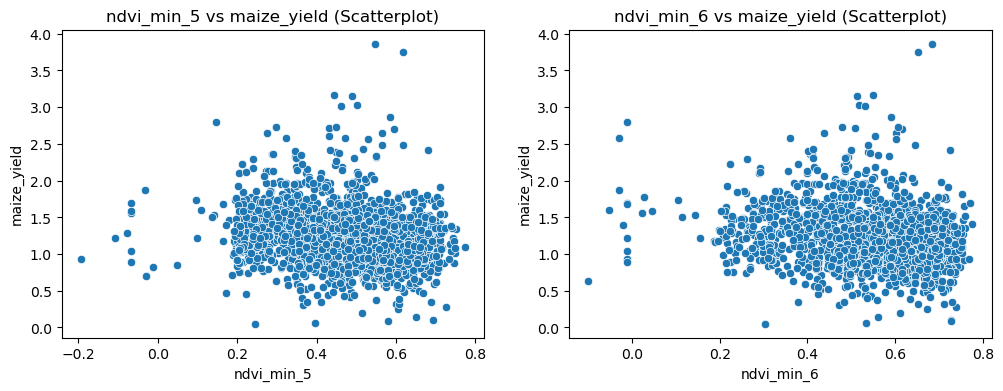

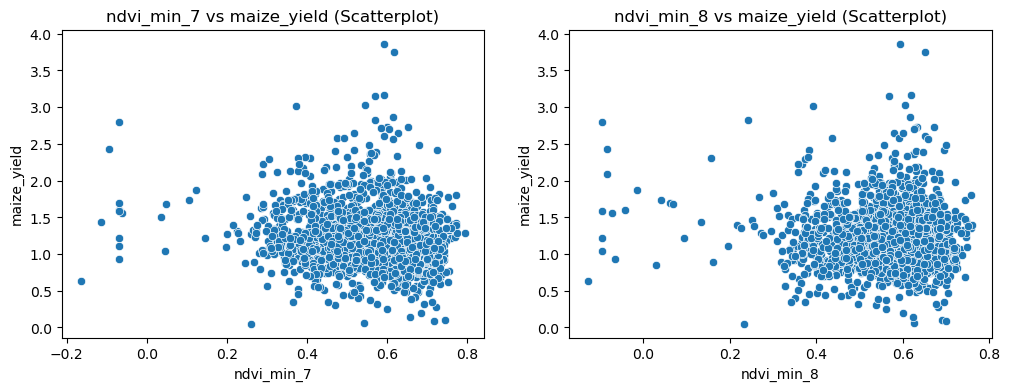

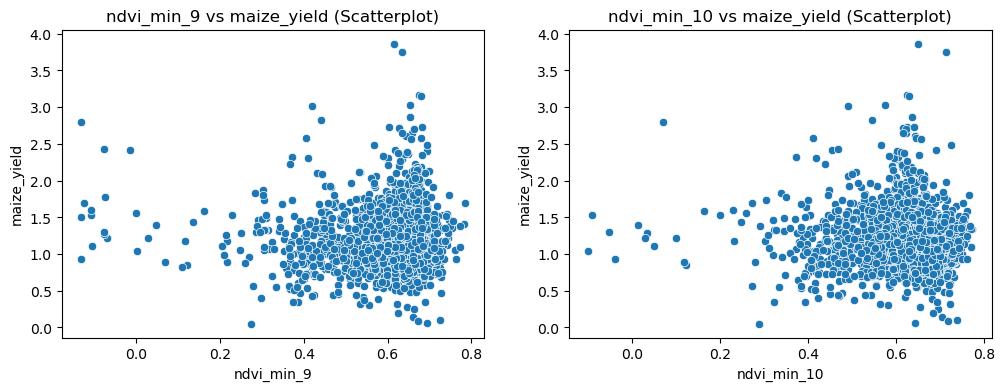

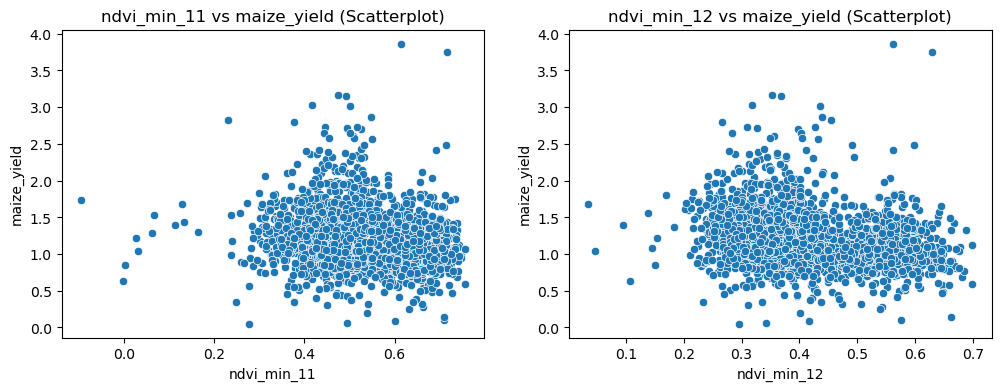

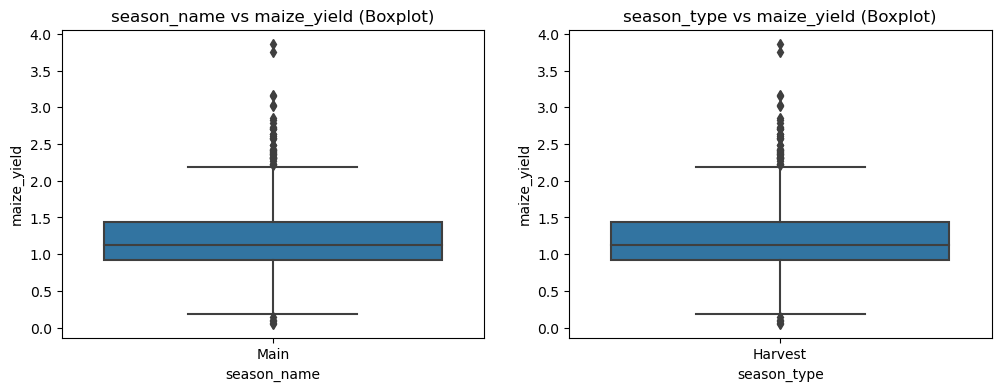

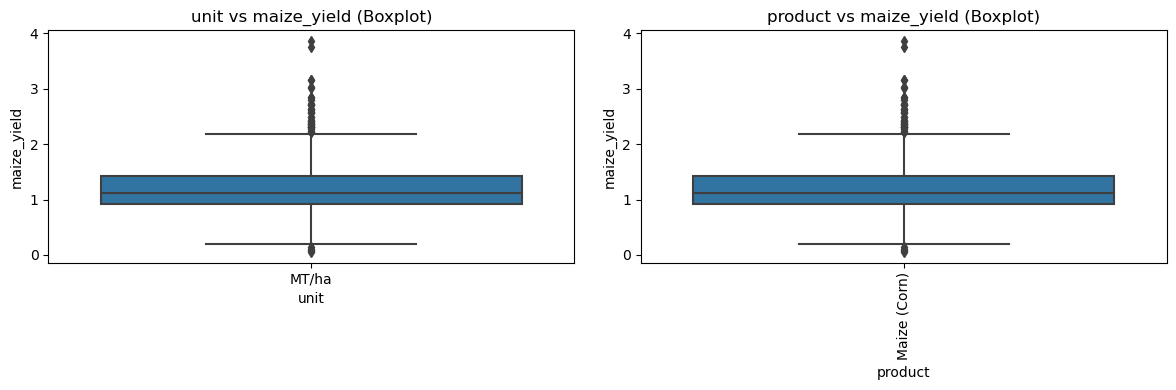

In [69]:
plot_target_vs_features(wide_modis_data_df_stats,target="maize_yield")

In [70]:
#Rmove NA from the dataframe before Modeling
wide_modis_data_df_stats_ml=wide_modis_data_df_stats.dropna()
wide_modis_data_df_stats_ml.shape

(1891, 81)

In [71]:
#-----------------------------------Remind of the libraries used for modeling

from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [72]:
#--------------------------------Data preparation and feature engineering

# Select vegetation-index features
num_features = [
    col for col in wide_modis_data_df_stats_ml.columns
    if col.startswith(("ndvi_", "evi_"))
]

cat_features=["Commune"]

features=num_features+cat_features
target="maize_yield"

X = wide_modis_data_df_stats_ml[features]
y = wide_modis_data_df_stats_ml[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

alphas_array=np.logspace(-4, 4, 100)

In [73]:
#-----------------Commune level modeling of maize yield: general modeling without cross validation on R2 metric

#model = make_pipeline(
#    StandardScaler(),
#    RidgeCV(alphas=np.logspace(-4, 4, 100), cv=5)
#)

from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ), cat_features)
    ]
)

model = make_pipeline(
    preprocessor,
    RidgeCV(alphas=alphas_array, cv=10,fit_intercept=True,scoring="r2") # We choose 10 cross validation and r2_score for evaluation
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)


In [74]:
#---------------------Display of the model performance for Commune level data

print("Best alpha:", model.named_steps["ridgecv"].alpha_)
print("R²:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

Best alpha: 1.9179102616724888
R²: 0.3002483836984219
RMSE: 0.32089792553147556


In [75]:
model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['evi_max_1', 'evi_max_2',
                                                   'evi_max_3', 'evi_max_4',
                                                   'evi_max_5', 'evi_max_6',
                                                   'evi_max_7', 'evi_max_8',
                                                   'evi_max_9', 'evi_max_10',
                                                   'evi_max_11', 'evi_max_12',
                                                   'evi_mean_1', 'evi_mean_2',
                                                   'evi_mean_3', 'evi_mean_4',
                                                   'evi_mean_5', 'evi_mean_6',
                                                   'evi_mean_7', 'evi_mean_8',
                                                   'evi_...
       1.38488637e+02, 1.66810054e+02, 2.00923300e+02, 2.42012826e+02,
       2.91505306e+02, 3.51119173e+02, 4.22924287e+02, 5.09413801e+02,
       6.13590727e+02, 7.39072203e+02, 8.90215085e+02, 1.07226722e+03,
       1.29154967e+03, 1.55567614e+03, 1.87381742e+03, 2.25701972e+03,
       2.71858824e+03, 3.27454916e+03, 3.94420606e+03, 4.75081016e+03,
       5.72236766e+03, 6.89261210e+03, 8.30217568e+03, 1.00000000e+04]),
                         cv=10, scoring='r2'))])

In [76]:
model.get_params()

{'memory': None,
 'steps': [('columntransformer',
   ColumnTransformer(transformers=[('num', StandardScaler(),
                                    ['evi_max_1', 'evi_max_2', 'evi_max_3',
                                     'evi_max_4', 'evi_max_5', 'evi_max_6',
                                     'evi_max_7', 'evi_max_8', 'evi_max_9',
                                     'evi_max_10', 'evi_max_11', 'evi_max_12',
                                     'evi_mean_1', 'evi_mean_2', 'evi_mean_3',
                                     'evi_mean_4', 'evi_mean_5', 'evi_mean_6',
                                     'evi_mean_7', 'evi_mean_8', 'evi_mean_9',
                                     'evi_mean_10', 'evi_mean_11', 'evi_mean_12',
                                     'evi_min_1', 'evi_min_2', 'evi_min_3',
                                     'evi_min_4', 'evi_min_5', 'evi_min_6', ...]),
                                   ('cat',
                                    OneHotEncoder(drop='first

## 3: Mean of maize yield and vegetation features

In [77]:
#----------------------- creation of wide_modis_data_df_stats_region data

select_featres=["Region","year"]+num_features+["maize_yield"]
wide_modis_data_df_stats_region=wide_modis_data_df_stats[select_featres].groupby(by=["Region","year"]).agg("mean").reset_index()


In [78]:
#-----------------Display of the head of the data

wide_modis_data_df_stats_region.head()

,Region,year,evi_max_1,evi_max_2,evi_max_3,evi_max_4,evi_max_5,evi_max_6,evi_max_7,evi_max_8,...,ndvi_min_4,ndvi_min_5,ndvi_min_6,ndvi_min_7,ndvi_min_8,ndvi_min_9,ndvi_min_10,ndvi_min_11,ndvi_min_12,maize_yield
0,Alibori,2002,NaN,NaN,NaN,NaN,NaN,NaN,0.512267,0.577450,...,NaN,NaN,NaN,0.418483,0.589783,0.611733,0.564867,0.401900,0.293100,1.258018
1,Alibori,2003,0.198500,0.196333,0.200217,0.266650,0.299550,0.445450,0.519450,0.577967,...,0.24485,0.251667,0.375233,0.507783,0.562433,0.539533,0.499983,0.386933,0.277417,1.394906
2,Alibori,2004,0.197333,0.177800,0.184983,0.241150,0.308783,0.426400,0.513000,0.576483,...,0.23430,0.256850,0.372683,0.479150,0.554017,0.604700,0.526567,0.364733,0.264417,1.472160
3,Alibori,2005,0.188683,0.169367,0.188150,0.228250,0.297783,0.440300,0.505017,0.591617,...,0.22495,0.241450,0.299500,0.476967,0.544983,0.591433,0.557983,0.382250,0.286400,1.249841
4,Alibori,2006,0.188883,0.194033,0.204083,0.225567,0.288583,0.393433,0.485467,0.554200,...,0.22185,0.255700,0.289933,0.392367,0.536467,0.571700,0.549967,0.419583,0.299283,1.361596


In [79]:
# ------------------------------------Drop na in wide_modis_data_df_stats_region

wide_modis_data_df_stats_region.dropna(inplace=True)

In [80]:
#---------------------------------------Modeling of maize yield mean in regional level

cat_features_regional=["Region"]

features_regional=num_features+cat_features_regional
target="maize_yield"

X_regional = wide_modis_data_df_stats_region[features_regional]
y_regional = wide_modis_data_df_stats_region[target]

# Assuming missing values have already been handled
X_train_regional, X_test_regional, y_train_regional, y_test_regional = train_test_split(
    X_regional, y_regional, test_size=0.2, random_state=42
)

preprocessor_regional = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ), cat_features_regional)
    ]
)

model_regional = make_pipeline(
    preprocessor_regional,
    RidgeCV(alphas=alphas_array, cv=10,scoring="r2") # We choose 10 cross validations and r2_score for evaluation
)

model_regional.fit(X_train_regional, y_train_regional)

y_pred_regional = model_regional.predict(X_test_regional)


In [81]:
#---------------------Display of the model performance for Region level data

print("Best alpha for regions:", model_regional.named_steps["ridgecv"].alpha_)
print("R² for regions test set:", r2_score(y_test_regional, y_pred_regional))
print("RMSE for regions test set:", np.sqrt(mean_squared_error(y_test_regional, y_pred_regional)))

Best alpha for regions: 4.862601580065354
R² for regions test set: 0.6076980880811874
RMSE for regions test set: 0.2061520229277957


In [82]:
model_regional.score(X_train_regional,y_train_regional)

0.6484649963619203

In [83]:
model_regional.get_params()

{'memory': None,
 'steps': [('columntransformer',
   ColumnTransformer(transformers=[('num', StandardScaler(),
                                    ['evi_max_1', 'evi_max_2', 'evi_max_3',
                                     'evi_max_4', 'evi_max_5', 'evi_max_6',
                                     'evi_max_7', 'evi_max_8', 'evi_max_9',
                                     'evi_max_10', 'evi_max_11', 'evi_max_12',
                                     'evi_mean_1', 'evi_mean_2', 'evi_mean_3',
                                     'evi_mean_4', 'evi_mean_5', 'evi_mean_6',
                                     'evi_mean_7', 'evi_mean_8', 'evi_mean_9',
                                     'evi_mean_10', 'evi_mean_11', 'evi_mean_12',
                                     'evi_min_1', 'evi_min_2', 'evi_min_3',
                                     'evi_min_4', 'evi_min_5', 'evi_min_6', ...]),
                                   ('cat',
                                    OneHotEncoder(drop='first

## Model comparison and interpretation

We can notice that the prediction result from the model using Commune level data does not give a good performance as the later one using Region level data. We have not much time to investigate what are the main reasons. But We can assume that it is because of the effect of smoothing (mean) of the features within regions.

## 4. Publication-quality scatter plots

In [84]:
# -----------------------------------Function to display scores
def display_score(obs, fcst):
    return {
        "R2 score": f"{r2_score(obs, fcst):.3f}",
        "RMSE score": f"{np.sqrt(mean_squared_error(obs, fcst)):.3f}",
        "Sample size": f"{len(obs):.0f}",
    }

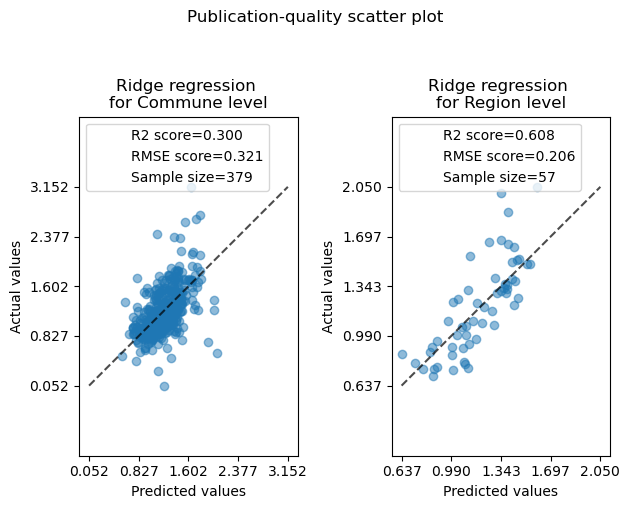

In [85]:
from sklearn.metrics import PredictionErrorDisplay

fig, (ax0, ax1) = plt.subplots(1, 2, sharey=False)

PredictionErrorDisplay.from_predictions(
    y_test,
    y_pred,
    kind="actual_vs_predicted",
    ax=ax0,
    scatter_kwargs={"alpha": 0.5},
)

PredictionErrorDisplay.from_predictions(
    y_test_regional,
    y_pred_regional,
    kind="actual_vs_predicted",
    ax=ax1,
    scatter_kwargs={"alpha": 0.5},
)

# Add the score in the legend of each axis
for ax, y_p, y_t in zip([ax0, ax1], [y_pred, y_pred_regional],[y_test, y_test_regional]):
    for name, score in display_score(y_t, y_p).items():
        ax.plot([], [], " ", label=f"{name}={score}")
    ax.legend(loc="upper left")

ax0.set_title("Ridge regression \nfor Commune level")
ax1.set_title("Ridge regression \nfor Region level")
fig.suptitle("Publication-quality scatter plot", y=1.05)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "2.4.png"))

# Task 3: AI Agent architecture proposal

### 1. Architecture design:

We think two architectures are possible for this task:
    
    1: the first one is what we can call unsignup scenario: in unsignup scenario, users do not need to have an account to ask for services. A LLM agent based can be implemented connecting users via api to Togo Service Public databases. We name this LLM agent "TogoEasyService". Thus, when a user wants an information on a demand his had asked for from the public administration, the user can upload ticket number, identity informations and automatically TogoEasyService will query databases and find out at which step the user's demand is. Before proceeding, the chatbot can ask for some identifcation informations like identity card number, email, etc... This first architecture is simple and easy to implement. It does not need to create a data management systems for users' login and users' activities. It only uses an API to communicate with the Togo Service Public Databases. But there is a problem: users can not display the history of their previous conversations with the public admistration and with TogoEasyService. There is also a vulnerability in implementing this architectre: any one can steal any user's information and get the informations of this user using the chatbot powered by TogoEasyService.
    
    2: The second architecture is user signup scenario: for this archiecture, we think user will be ask to crete their account and log in the Togo Public Sevice system. There will be a dashboard that will display each user's profile, his previous conversions and the position of his demands. For this archtitecture, a users activities data amanagement system must be implemented. We think the following data tables must be created: user_account_info(user_id, user_name,user_family_name, user_email, user_phone_number,user_birth_date,user_birth_location,user_location, user_identity_card_id,user_login,user_password), user_login_history(user_login,login_date,logout_date), public_services_info(service_id,service_name,service_description,service_demad_treatment_duration),user_conversation(conversation_id,conversation_title,conversion_content_json). There are a lot of possibilities but we can not list them all here because of lack of time to think and design a robust users data management system. After data system, we can think abut the UI. We think a dashboard is a good choice for users to easily display the informations about their demands. The state of the demands can be managed by a LLM agent that we can call AdvancedTogoEasyService. AdvancedTogoEasyService will in real time query the databaes to identify the state of users's demands. And in AdvancedTogoEasyService dialog panel, a user can ask a question and and get a response based on the the state of demands in Togo Public Service databases. As each user has an account, when a demand for a user is fullfilled, we can design an automatic email sending system that can alert the user by emailing that his demand has been treated. In the user dashboard, we can implement demand treatment steps tracking system that displays at which step a certain demand from the user is stopped.

### 2. Evaluation & monitoring

The chatbot performance is based on the disponibility of the chatbot and the quality of the informations that the chatbot retrieves to the users.

Chatbot disponibility: the chatbot must be available to respond to many users at the same time. For this purpose we have to implement a robust api dialog system.

Quality of conversations: The generated text from the chatbot must tell truth because the informations needed by users are for public good and professional purposes. False informations must by all means be avoided. Thus, the LLM agent must be calibrated through fine tuning to avoid hallucinations and false informations.


### 3. Assumptions

We think to use stacks like:

    -API: FastAPI from Python or Plumber API from R to communicate between the user prompt and Togo Public services databases.
    - PostgreSQL database management system: to create databases and datatables to allow users informations and conversations storage.
    - A LLM frontier or open source model to allow automatic informations retreival to users via the chatbot.
    - UI: html, javascript, css